# Evaluación Parcial N°3: Pipeline Integrado de Deep Learning para Lenguaje de Señas (ASL)
**TLY1101 Técnicas Avanzadas de Machine Learning I**

Continúa la EP1 (MLP, `train_sign.ipynb`) y la EP2 (CNN, `train_sign_cnn.ipynb`). Se mantiene **el mismo problema, dataset, variante, split y semilla** para conservar la trazabilidad y comparar de forma objetiva una MLP optimizada con una CNN final.

## Problema y objetivo
Clasificar imágenes 28×28 en escala de grises de letras del alfabeto ASL (variante de 6 letras de puño cerrado: A, E, M, N, S, T) con **Sign Language MNIST**.

**KPIs** (los mismos de la EP1 y la EP2, fijados antes de entrenar y sin ajustarlos):

| KPI | Meta |
|---|---|
| Accuracy (test final) | ≥ 80% |
| F1-Score macro (test final) | ≥ 75% |

## Arquitectura del Pipeline Integrado
Todo el flujo se organiza en **funciones reutilizables** que reciben sus parámetros por diccionario. Así, la regularización, la búsqueda de hiperparámetros y la auditoría de los pasos siguientes solo cambian los parámetros y no el código del pipeline.

| # | Etapa | Función(es) | Propósito |
|---|---|---|---|
| 1 | Carga de datos | `load_data` | Leer los CSV y construir la variante de 6 letras |
| 2 | Análisis exploratorio | `plot_eda` | Verificar calidad, balance de clases y patrones visuales |
| 3 | Preprocesamiento | `preprocess` | Normalizar, codificar etiquetas y separar train / validación / test |
| 4 | Construcción del modelo | `build_mlp`, `build_cnn` | Crear arquitecturas parametrizadas (con ganchos de regularización) |
| 5 | Entrenamiento | `train_model` | Entrenar con Early Stopping sobre `val_loss` |
| 6 | Regularización | parámetros `dropout`, `l2`, `batch_norm`, `augment` y Early Stopping | Reducir el sobreajuste y mejorar la generalización |
| 7 | Evaluación | `evaluate_model`, `summarize_run` | Accuracy, Precision, Recall, F1 y ROC-AUC |
| 8 | Auditoría | *(pendiente)* | Sesgos, XAI e implicancias éticas |
| 9 | Optimización | `run_experiment` | Experimentos controlados de hiperparámetros *(se usa en el paso 3)* |

**Alcance de este notebook por ahora:** base modular del pipeline (etapas 1 a 5 y 7), reproducción de las líneas base MLP y CNN de la EP1 y la EP2 (sección 6) y **análisis del efecto de cada técnica de regularización** (sección 7). Las líneas base son el punto de comparación de todo lo que sigue.

## 1. Configuración y reproducibilidad
Toda la configuración del pipeline está en un solo lugar. Los valores por defecto de `MLP_BASE` y `CNN_BASE` reproducen exactamente las arquitecturas de la EP1 y la EP2 (sin regularización).

In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             precision_recall_fscore_support)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Dense, Conv2D, MaxPooling2D, Flatten,
                                     Dropout, BatchNormalization, Activation,
                                     RandomTranslation, RandomRotation, RandomZoom)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam

CONFIG = {
    'seed': 42,
    'letras_variante': ['A', 'E', 'M', 'N', 'S', 'T'],   # misma variante de la EP1 y la EP2
    'val_fraccion_del_test': 0.50,                        # el archivo de test se divide 50/50 (validación / test final)
    'epochs': 30,
    'batch_size': 64,
    'patience': 5,                                        # Early Stopping sobre val_loss
    'early_stopping': True,                               # se apaga solo para medir su efecto (sección 7.3)
    'paths': {
        'train': 'data/sign_mnist_train.csv',
        'test': 'data/sign_mnist_test.csv',
        'images': 'images',
        'models': 'models',
    },
}

# Hiperparámetros por defecto = líneas base de la EP1 (MLP) y la EP2 (CNN), SIN regularización
MLP_BASE = dict(units=(128,), dropout=0.0, l2=0.0, batch_norm=False, lr=1e-3)
CNN_BASE = dict(filters=(32, 64), dense_units=128, dropout=0.0, l2=0.0, batch_norm=False, lr=1e-3, augment=None)


def set_global_seed(seed):
    """Fija todas las semillas (Python, NumPy, TensorFlow) para que los experimentos sean reproducibles."""
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


set_global_seed(CONFIG['seed'])
os.makedirs(CONFIG['paths']['images'], exist_ok=True)
os.makedirs(CONFIG['paths']['models'], exist_ok=True)
print(f"TensorFlow {tf.__version__} | semilla global = {CONFIG['seed']}")

I0000 00:00:1795172683.570980    3296 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | semilla global = 42


I0000 00:00:1795172685.194993    3296 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Carga de datos y análisis exploratorio (etapas 1 y 2)
`load_data` replica la variante de la EP1 y la EP2: se excluyen J (9) y Z (25), que requieren movimiento, y luego se conservan solo las letras de la variante con el 100% de sus imágenes.

In [2]:
def load_data(cfg):
    """Carga los CSV de Sign Language MNIST y filtra la variante de letras definida en cfg.

    Devuelve (df_train, df_test, label_mapping, labels_variante), donde label_mapping
    asocia el código numérico original con su letra.
    """
    df_train_full = pd.read_csv(cfg['paths']['train'])
    df_test_full = pd.read_csv(cfg['paths']['test'])

    # Se excluyen J=9 y Z=25 (requieren movimiento); las 24 etiquetas restantes se mapean al alfabeto
    valid_labels = sorted(set(range(25)) - {9})
    alphabet = "ABCDEFGHIKLMNOPQRSTUVWXY"
    mapping_full = {lab: alphabet[i] for i, lab in enumerate(valid_labels)}

    letra_a_label = {letra: lab for lab, letra in mapping_full.items()}
    labels_variante = sorted(letra_a_label[l] for l in cfg['letras_variante'])
    label_mapping = {lab: mapping_full[lab] for lab in labels_variante}

    df_train = df_train_full[df_train_full['label'].isin(labels_variante)].copy()
    df_test = df_test_full[df_test_full['label'].isin(labels_variante)].copy()
    return df_train, df_test, label_mapping, labels_variante


df_train, df_test, label_mapping, labels_variante = load_data(CONFIG)
letras = list(label_mapping.values())
N_CLASES = len(letras)

print(f"Variante {letras}: train {df_train.shape}, test {df_test.shape}")
print(f"Nulos en train: {df_train.isnull().sum().sum()} | Duplicados en train: {df_train.duplicated().sum()}")
print("Imágenes por clase en train:", df_train['label'].map(label_mapping).value_counts().reindex(letras).to_dict())
print("Imágenes por clase en test :", df_test['label'].map(label_mapping).value_counts().reindex(letras).to_dict())

Variante ['A', 'E', 'M', 'N', 'S', 'T']: train (6674, 785), test (2008, 785)
Nulos en train: 0 | Duplicados en train: 0
Imágenes por clase en train: {'A': 1126, 'E': 957, 'M': 1055, 'N': 1151, 'S': 1199, 'T': 1186}
Imágenes por clase en test : {'A': 331, 'E': 498, 'M': 394, 'N': 291, 'S': 246, 'T': 248}


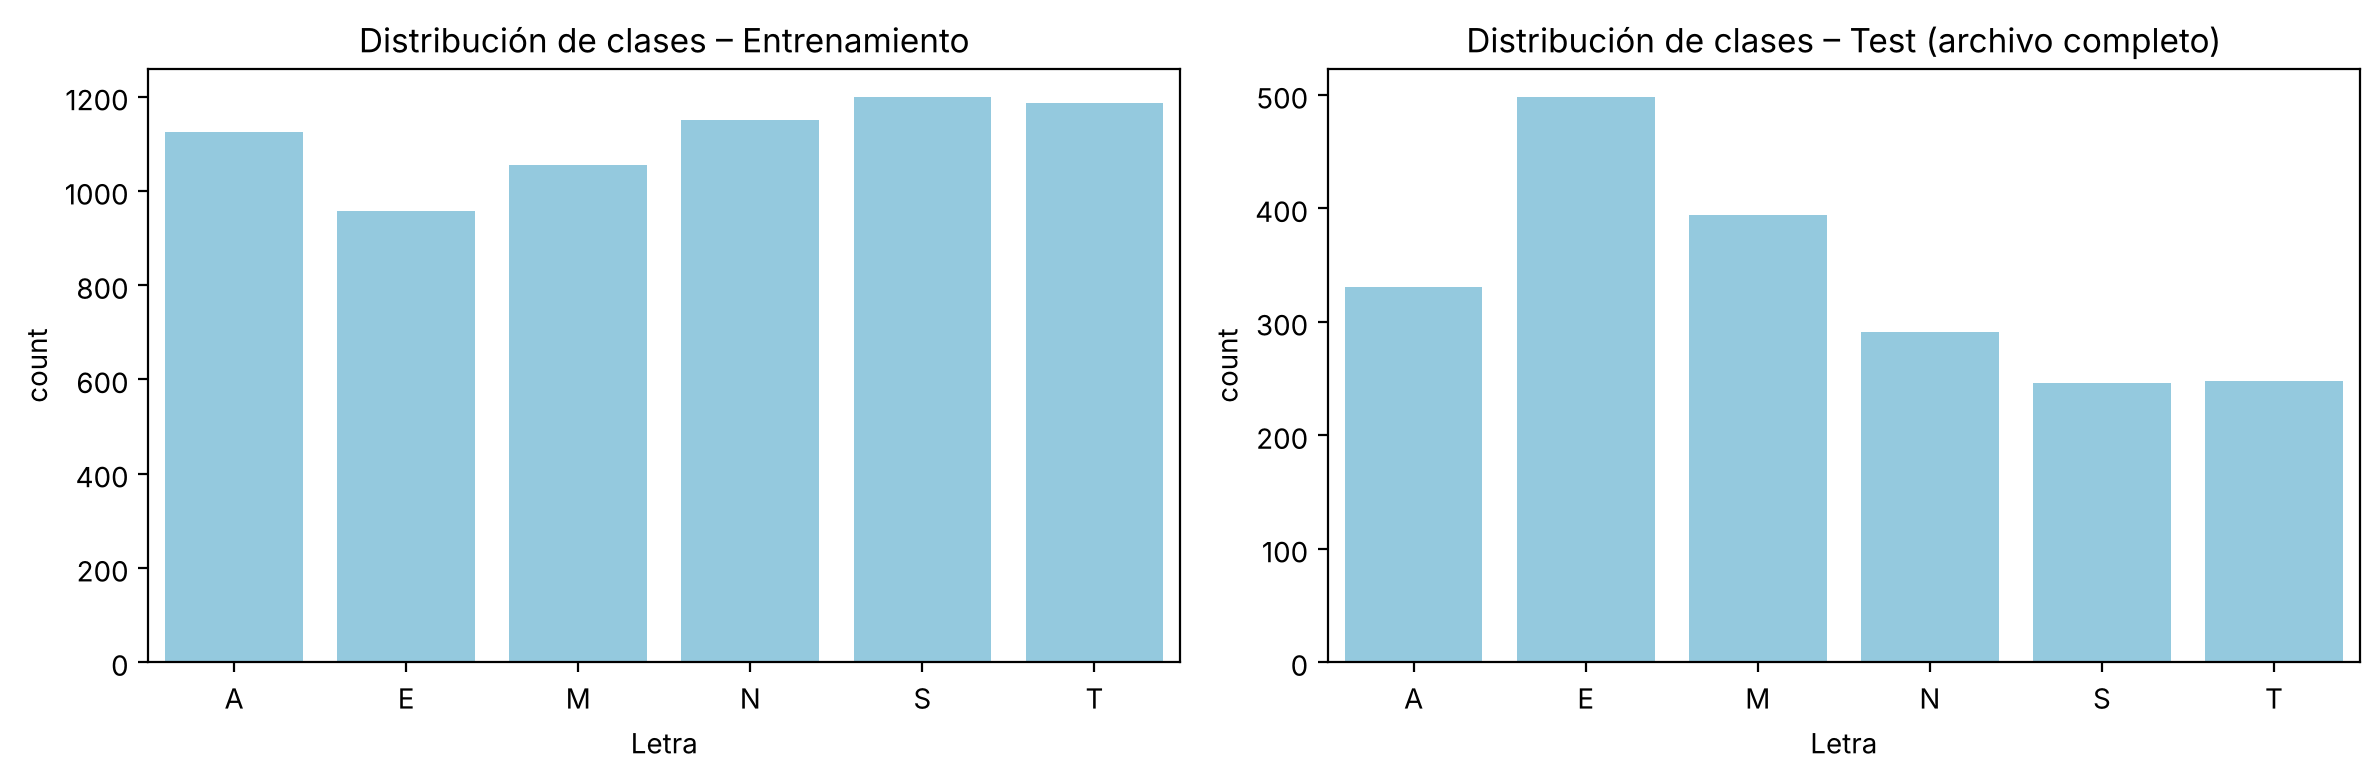

Razón máx/mín por clase – train: 1.25 | test: 2.02
Píxeles: mín 0, máx 255, media 164.2, desv. 47.4


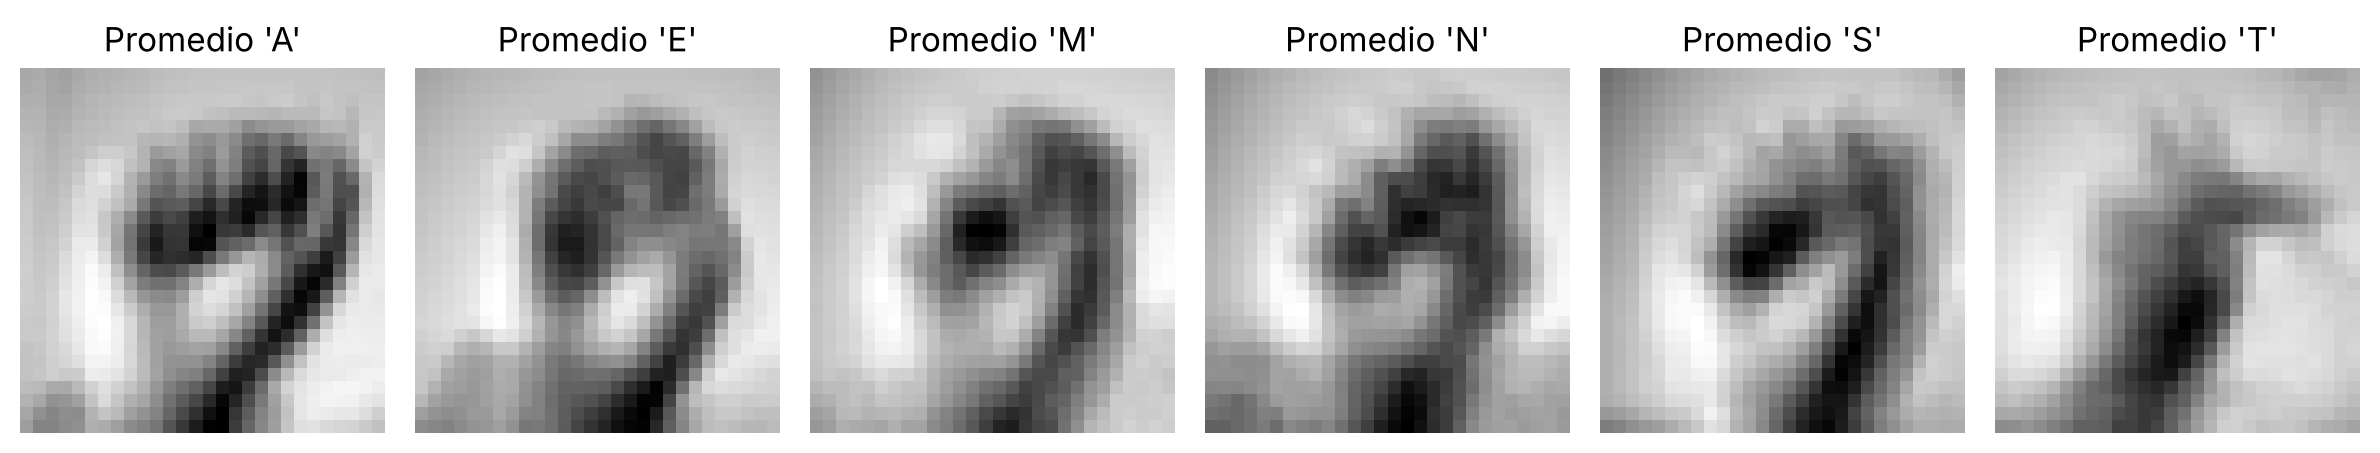

In [3]:
def plot_eda(df_train, df_test, label_mapping, labels_variante, save_dir):
    """EDA: distribución de clases (train y test), rango de píxeles e imagen promedio por clase."""
    letras = [label_mapping[l] for l in labels_variante]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, df_, titulo in [(axes[0], df_train, 'Entrenamiento'), (axes[1], df_test, 'Test (archivo completo)')]:
        sns.countplot(x='label', data=df_, order=labels_variante, color='skyblue', ax=ax)
        ax.set_xticks(range(len(letras))); ax.set_xticklabels(letras)
        ax.set_xlabel('Letra'); ax.set_title(f'Distribución de clases – {titulo}')
    plt.tight_layout(); plt.savefig(f'{save_dir}/ep3_distribucion_clases.png'); plt.show()

    c_tr, c_te = df_train['label'].value_counts(), df_test['label'].value_counts()
    print(f"Razón máx/mín por clase – train: {c_tr.max()/c_tr.min():.2f} | test: {c_te.max()/c_te.min():.2f}")
    pix = df_train.drop('label', axis=1).values
    print(f"Píxeles: mín {pix.min()}, máx {pix.max()}, media {pix.mean():.1f}, desv. {pix.std():.1f}")

    fig, axes = plt.subplots(1, len(letras), figsize=(12, 2.5))
    for ax, lab in zip(axes, labels_variante):
        prom = df_train[df_train['label'] == lab].iloc[:, 1:].values.mean(axis=0).reshape(28, 28)
        ax.imshow(prom, cmap='gray'); ax.set_title(f"Promedio '{label_mapping[lab]}'"); ax.axis('off')
    plt.tight_layout(); plt.savefig(f'{save_dir}/ep3_imagen_promedio_clases.png'); plt.show()


plot_eda(df_train, df_test, label_mapping, labels_variante, CONFIG['paths']['images'])

**Lectura del EDA (los mismos hallazgos de la EP1 y la EP2):**
- Sin nulos ni duplicados; píxeles en [0, 255] y el train razonablemente balanceado.
- El test **no** está balanceado (hay clases con casi el doble de imágenes que otras), por eso además del accuracy se reportan Precision, Recall, F1 macro y ROC-AUC.
- Las imágenes promedio de M, N y S son visualmente parecidas (puño cerrado con distinta posición del pulgar). Se espera que sean las clases más confundidas.

## 3. Preprocesamiento (etapa 3)
Igual que en la EP1 y la EP2: normalización /255, one-hot y **validación independiente**. Las imágenes de train son aumentaciones de pocas manos, así que el train se usa solo para entrenar y el archivo de test (otras manos) se divide 50/50 estratificado en **validación** (Early Stopping y selección de hiperparámetros) y **test final** (solo para reportar). `preprocess` entrega cada partición en dos formatos: aplanado (MLP) y tensor 28×28×1 (CNN).

In [4]:
def preprocess(df_train, df_test, cfg):
    """Normaliza, codifica y separa los datos. Devuelve un dict con las particiones 'train', 'val' y 'test'.

    Cada partición contiene: 'flat' (N, 784) para la MLP, 'img' (N, 28, 28, 1) para la CNN,
    'y' (one-hot) e 'y_int' (índice de clase).
    """
    seed = cfg['seed']
    X_tr = df_train.drop('label', axis=1).values / 255.0
    X_te_all = df_test.drop('label', axis=1).values / 255.0

    lb = LabelBinarizer()
    y_tr = lb.fit_transform(df_train['label'].values)
    y_te_all = lb.transform(df_test['label'].values)

    X_val, X_te, y_val, y_te, _, _ = train_test_split(
        X_te_all, y_te_all, df_test['label'].values,
        test_size=cfg['val_fraccion_del_test'], stratify=df_test['label'].values, random_state=seed)

    def pack(X, y):
        return {'flat': X, 'img': X.reshape(-1, 28, 28, 1), 'y': y, 'y_int': np.argmax(y, axis=1)}

    return {'train': pack(X_tr, y_tr), 'val': pack(X_val, y_val), 'test': pack(X_te, y_te)}


data = preprocess(df_train, df_test, CONFIG)
for split, d in data.items():
    print(f"{split:5s} -> flat {d['flat'].shape} | img {d['img'].shape} | y {d['y'].shape}")
print(f"Rango de píxeles tras normalizar: [{data['train']['flat'].min():.1f}, {data['train']['flat'].max():.1f}]")

train -> flat (6674, 784) | img (6674, 28, 28, 1) | y (6674, 6)
val   -> flat (1004, 784) | img (1004, 28, 28, 1) | y (1004, 6)
test  -> flat (1004, 784) | img (1004, 28, 28, 1) | y (1004, 6)
Rango de píxeles tras normalizar: [0.0, 1.0]


## 4. Construcción de modelos (etapa 4)
`build_mlp` y `build_cnn` reciben un diccionario de hiperparámetros. Con los valores por defecto (`MLP_BASE`, `CNN_BASE`) reproducen las arquitecturas de la EP1 y la EP2. Las perillas `dropout`, `l2` y `batch_norm` (y `augment` en la CNN) están **apagadas** por defecto y se activan en la sección 7.

Convención: con `batch_norm=True` cada bloque es *Capa lineal → BatchNorm → ReLU*. Se nombra `conv{i}` a la salida de cada bloque convolucional (post-ReLU) para poder usarla después en Grad-CAM.

In [5]:
def build_mlp(params, n_classes=N_CLASES):
    """MLP parametrizada. params: units (tupla), dropout, l2, batch_norm, lr."""
    reg = regularizers.l2(params['l2']) if params['l2'] > 0 else None
    model = Sequential([Input(shape=(784,))])
    for u in params['units']:
        if params['batch_norm']:
            model.add(Dense(u, kernel_regularizer=reg, use_bias=False))
            model.add(BatchNormalization())
            model.add(Activation('relu'))
        else:
            model.add(Dense(u, activation='relu', kernel_regularizer=reg))
        if params['dropout'] > 0:
            model.add(Dropout(params['dropout']))
    model.add(Dense(n_classes, activation='softmax'))
    model.compile(optimizer=Adam(params['lr']), loss='categorical_crossentropy', metrics=['accuracy'])
    return model


def build_cnn(params, n_classes=N_CLASES):
    """CNN parametrizada. params: filters (tupla), dense_units, dropout, l2, batch_norm, lr y augment.

    augment (dict o None): data augmentation en línea con translation, rotation y zoom (fracciones).
    Las capas aleatorias solo actúan en entrenamiento; en validación, test y predicción son identidad.
    No se usa volteo horizontal: espejaría la mano y cambiaría la seña.
    """
    reg = regularizers.l2(params['l2']) if params['l2'] > 0 else None
    model = Sequential([Input(shape=(28, 28, 1))])
    aug = params.get('augment')
    if aug:
        model.add(RandomTranslation(aug['translation'], aug['translation'], fill_mode='nearest', name='aug_traslacion'))
        model.add(RandomRotation(aug['rotation'], fill_mode='nearest', name='aug_rotacion'))
        model.add(RandomZoom(aug['zoom'], fill_mode='nearest', name='aug_zoom'))
    for i, f in enumerate(params['filters'], start=1):
        if params['batch_norm']:
            model.add(Conv2D(f, (3, 3), padding='same', kernel_regularizer=reg, use_bias=False, name=f'conv{i}_lineal'))
            model.add(BatchNormalization(name=f'bn{i}'))
            model.add(Activation('relu', name=f'conv{i}'))
        else:
            model.add(Conv2D(f, (3, 3), activation='relu', padding='same', kernel_regularizer=reg, name=f'conv{i}'))
        model.add(MaxPooling2D((2, 2), name=f'pool{i}'))
    model.add(Flatten())
    model.add(Dense(params['dense_units'], activation='relu', kernel_regularizer=reg))
    if params['dropout'] > 0:
        model.add(Dropout(params['dropout']))
    model.add(Dense(n_classes, activation='softmax'))
    model.compile(optimizer=Adam(params['lr']), loss='categorical_crossentropy', metrics=['accuracy'])
    return model


BUILDERS = {'mlp': build_mlp, 'cnn': build_cnn}
print(f"Parámetros MLP base: {build_mlp(MLP_BASE).count_params():,} | CNN base: {build_cnn(CNN_BASE).count_params():,}")

Parámetros MLP base: 101,254 | CNN base: 421,126


## 5. Entrenamiento y evaluación (etapas 5 y 7)
- `train_model`: entrena con Early Stopping sobre `val_loss` (`restore_best_weights=True`) y mide el tiempo.
- `evaluate_model`: calcula Accuracy, Precision, Recall, F1 (macro) y **ROC-AUC** (*one-vs-rest*, macro) sobre la partición pedida.
- `run_experiment`: une construcción, entrenamiento y evaluación de **una configuración** con la semilla fija. Es la unidad que reutilizarán la regularización y la búsqueda de hiperparámetros.
- `summarize_run`: resume un experimento en una fila de tabla comparativa.

In [6]:
def get_inputs(data, split, kind):
    """Devuelve la entrada correcta según la arquitectura: 'flat' para la MLP y 'img' para la CNN."""
    return data[split]['flat' if kind == 'mlp' else 'img']


def train_model(model, data, kind, cfg):
    """Entrena con Early Stopping sobre val_loss (si cfg['early_stopping']). Devuelve (history, tiempo_en_segundos)."""
    callbacks = []
    if cfg.get('early_stopping', True):
        callbacks.append(EarlyStopping(monitor='val_loss', patience=cfg['patience'], restore_best_weights=True))
    t0 = time.time()
    history = model.fit(get_inputs(data, 'train', kind), data['train']['y'],
                        validation_data=(get_inputs(data, 'val', kind), data['val']['y']),
                        epochs=cfg['epochs'], batch_size=cfg['batch_size'],
                        callbacks=callbacks, verbose=0)
    return history, time.time() - t0


def evaluate_model(model, data, kind, split='test'):
    """Métricas sobre una partición. Devuelve (dict de métricas, y_pred, probabilidades)."""
    probs = model.predict(get_inputs(data, split, kind), verbose=0)
    y_true, y_pred = data[split]['y_int'], np.argmax(probs, axis=1)
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro'),
        'recall_macro': recall_score(y_true, y_pred, average='macro'),
        'f1_macro': f1_score(y_true, y_pred, average='macro'),
        'roc_auc_macro': roc_auc_score(data[split]['y'], probs, average='macro', multi_class='ovr'),
    }
    return metrics, y_pred, probs


def run_experiment(name, kind, params, data, cfg):
    """Construye, entrena y evalúa UNA configuración con la semilla fija.

    kind: 'mlp' o 'cnn'. Devuelve un dict con modelo, history, tiempo, métricas de val/test y predicciones.
    """
    set_global_seed(cfg['seed'])
    model = BUILDERS[kind](params)
    history, tiempo = train_model(model, data, kind, cfg)
    m_val, _, _ = evaluate_model(model, data, kind, 'val')
    m_test, y_pred, probs = evaluate_model(model, data, kind, 'test')
    return {'name': name, 'kind': kind, 'params': params, 'model': model, 'history': history,
            'early_stopping': cfg.get('early_stopping', True), 'tiempo': tiempo, 'val': m_val, 'test': m_test, 'y_pred': y_pred, 'probs': probs}


def summarize_run(r):
    """Fila de tabla comparativa de un experimento (val + test + sobreajuste + costo)."""
    h = r['history'].history
    # Con Early Stopping el modelo evaluado es el de la mejor época (val_loss); sin él, el de la última época
    best = int(np.argmin(h['val_loss'])) if r.get('early_stopping', True) else len(h['loss']) - 1
    return {'Modelo': r['name'], 'Parámetros': r['model'].count_params(), 'Épocas': len(h['loss']),
            'Época elegida': best + 1, 'Tiempo (s)': round(r['tiempo'], 1),
            'Val Loss': round(h['val_loss'][best], 3), 'Val Acc': round(h['val_accuracy'][best], 3),
            'Train Acc': round(h['accuracy'][best], 3),
            'Brecha train-val': round(h['accuracy'][best] - h['val_accuracy'][best], 3),
            'Test Acc': round(r['test']['accuracy'], 3), 'Test Precision': round(r['test']['precision_macro'], 3),
            'Test Recall': round(r['test']['recall_macro'], 3), 'Test F1': round(r['test']['f1_macro'], 3),
            'Test ROC-AUC': round(r['test']['roc_auc_macro'], 3)}

In [7]:
def plot_history(results, save_path=None, title='Curvas de aprendizaje'):
    """Curvas de pérdida y exactitud (train: línea punteada, validación: línea continua) de uno o más experimentos."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for r, c in zip(results, plt.rcParams['axes.prop_cycle'].by_key()['color']):
        h = r['history'].history
        best = int(np.argmin(h['val_loss']))
        axes[0].plot(h['val_loss'], color=c, label=f"{r['name']} (val)")
        axes[0].plot(h['loss'], color=c, linestyle='--', label=f"{r['name']} (train)")
        axes[1].plot(h['val_accuracy'], color=c, label=f"{r['name']} (val)")
        axes[1].plot(h['accuracy'], color=c, linestyle='--', label=f"{r['name']} (train)")
        axes[0].axvline(best, color=c, alpha=0.3); axes[1].axvline(best, color=c, alpha=0.3)
    axes[0].set_title(f'{title}: pérdida'); axes[1].set_title(f'{title}: exactitud')
    for ax in axes:
        ax.set_xlabel('Época'); ax.legend(fontsize=8)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()


def plot_confusion(y_true, y_pred, letras, title, save_path=None):
    """Matriz de confusión (conteos) con las letras como etiquetas."""
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=letras, yticklabels=letras)
    plt.title(title); plt.xlabel('Predicho'); plt.ylabel('Real')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()


def top_confusiones(y_true, y_pred, letras, n=5):
    """Las n confusiones más frecuentes (real -> predicho) y el total de errores."""
    c = Counter((letras[r], letras[p]) for r, p in zip(y_true, y_pred) if r != p)
    return c.most_common(n), sum(c.values())

## 6. Líneas base: MLP y CNN sin regularización
Se ejecuta el pipeline completo con los parámetros base. Son las **referencias** contra las que se medirá el efecto de cada técnica de regularización y de cada hiperparámetro en los pasos siguientes.

In [8]:
baselines = {
    'MLP base (128)': run_experiment('MLP base (128)', 'mlp', MLP_BASE, data, CONFIG),
    'CNN base (32-64 + Dense 128)': run_experiment('CNN base (32-64 + Dense 128)', 'cnn', CNN_BASE, data, CONFIG),
}
df_base = pd.DataFrame([summarize_run(r) for r in baselines.values()]).set_index('Modelo').T
display(df_base)
df_base.to_csv(f"{CONFIG['paths']['images']}/ep3_baselines_tabla.csv")

Modelo,MLP base (128),CNN base (32-64 + Dense 128)
Parámetros,101254.000,421126.000
Épocas,18.000,9.000
Época elegida,13.000,4.000
Tiempo (s),7.500,39.600
Val Loss,0.574,0.277
Val Acc,0.811,0.926
Train Acc,0.993,1.000
Brecha train-val,0.182,0.073
Test Acc,0.794,0.925
Test Precision,0.782,0.920


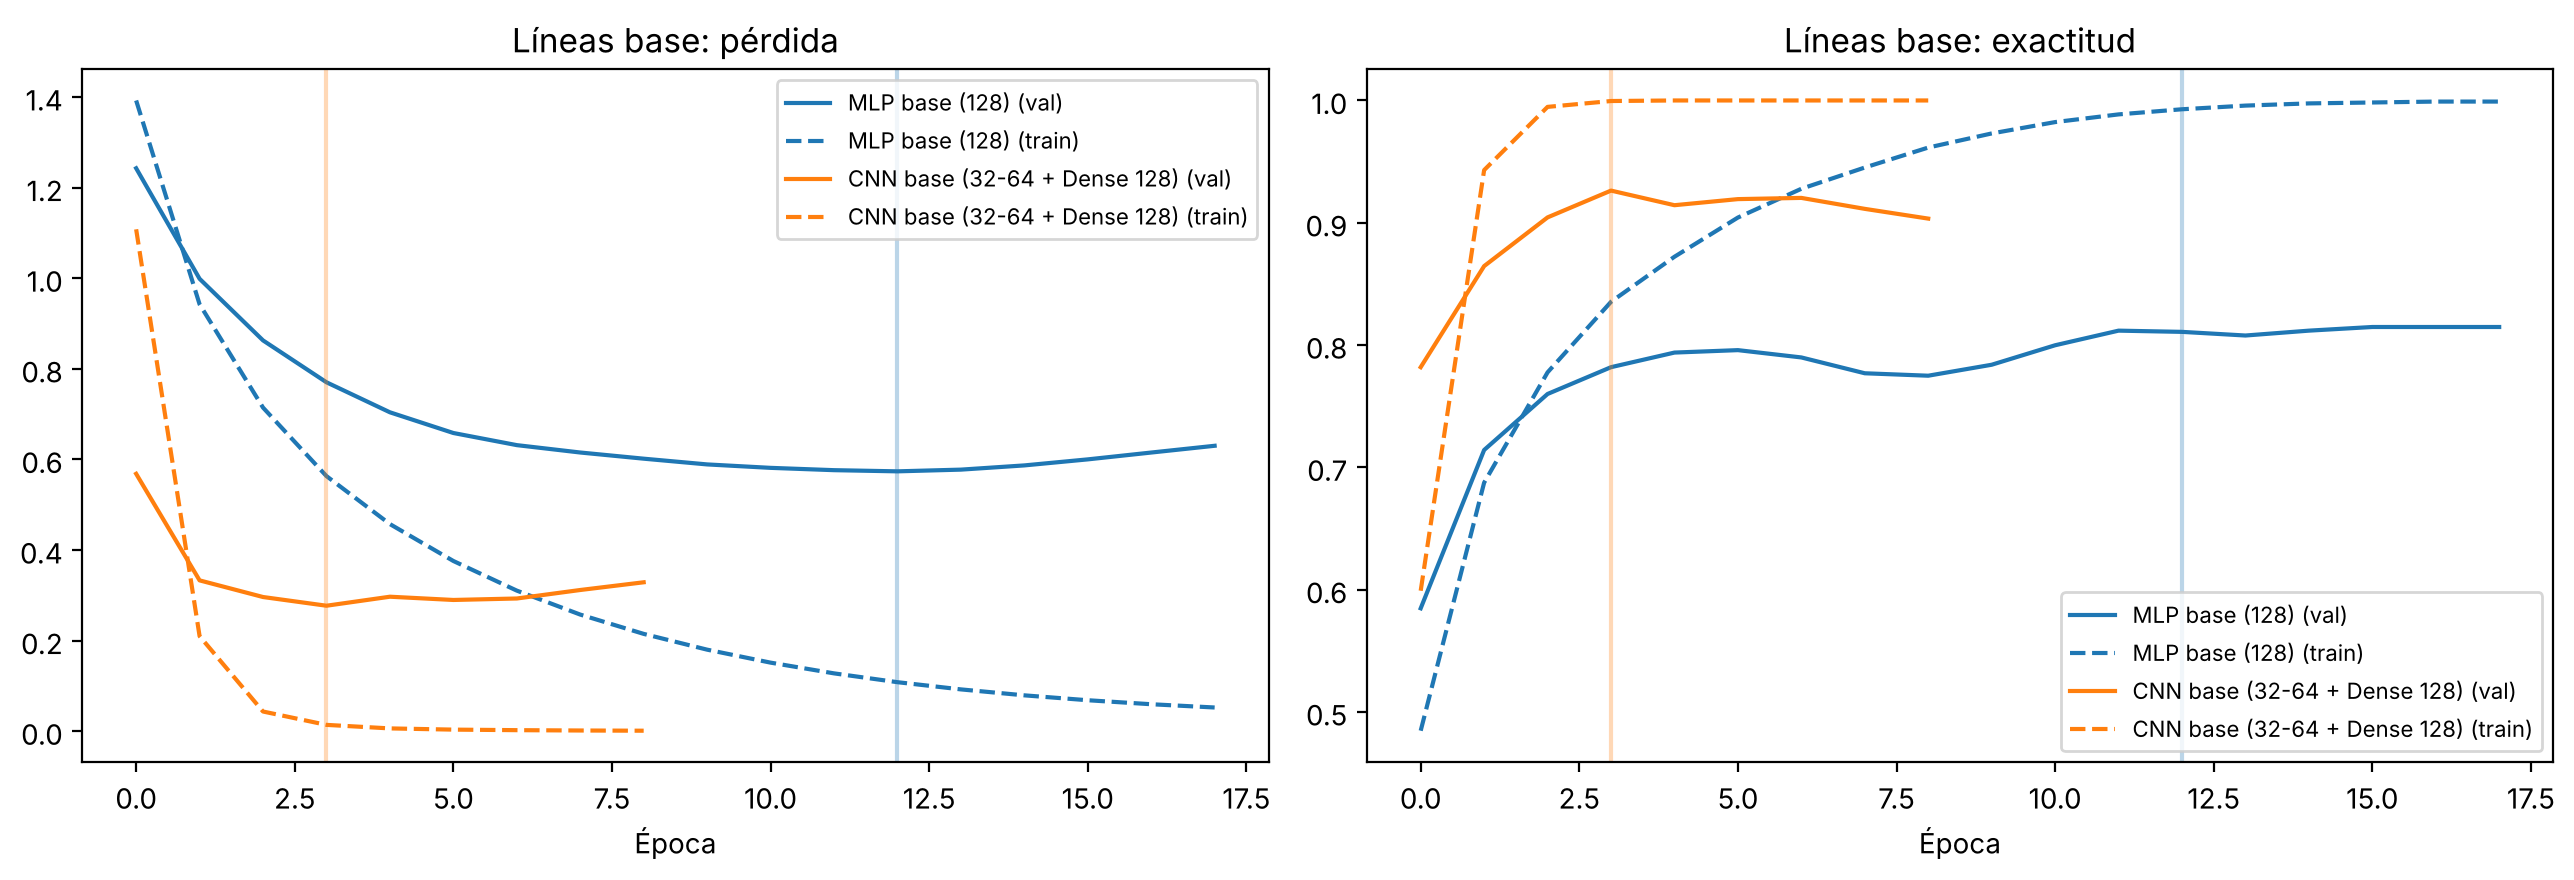

In [9]:
plot_history(list(baselines.values()), save_path=f"{CONFIG['paths']['images']}/ep3_curvas_baselines.png", title='Líneas base')

### Control de trazabilidad con la EP1 y la EP2
Las líneas base de este notebook deben reproducir los resultados reportados antes (accuracy en test final: MLP 79,4% y CNN 92,5%). Diferencias de alrededor de 1 punto porcentual son esperables por diferencias numéricas de CPU y librerías.

In [10]:
REFERENCIA = {'MLP base (128)': 0.794, 'CNN base (32-64 + Dense 128)': 0.925}   # test final, EP1 y EP2
for nombre, ref in REFERENCIA.items():
    acc = baselines[nombre]['test']['accuracy']
    estado = 'OK' if abs(acc - ref) <= 0.02 else 'REVISAR'
    print(f"{nombre:30s} accuracy test = {acc:.3f} | referencia = {ref:.3f} | diferencia = {acc - ref:+.3f} -> {estado}")

MLP base (128)                 accuracy test = 0.794 | referencia = 0.794 | diferencia = -0.000 -> OK
CNN base (32-64 + Dense 128)   accuracy test = 0.925 | referencia = 0.925 | diferencia = +0.000 -> OK


=== MLP base (128) ===
              precision    recall  f1-score   support

           A      0.892     1.000     0.943       166
           E      0.893     0.839     0.865       249
           M      0.740     0.665     0.701       197
           N      0.746     0.690     0.717       145
           S      0.472     0.545     0.506       123
           T      0.947     1.000     0.973       124

    accuracy                          0.794      1004
   macro avg      0.782     0.790     0.784      1004
weighted avg      0.797     0.794     0.794      1004

207 errores de 1004 imágenes. Top 5 confusiones (real -> predicho): M->S (42), S->M (31), E->S (30), N->A (20), N->M (15) 

=== CNN base (32-64 + Dense 128) ===
              precision    recall  f1-score   support

           A      0.949     1.000     0.974       166
           E      0.953     0.988     0.970       249
           M      0.898     0.893     0.896       197
           N      0.924     0.834     0.877       145
  

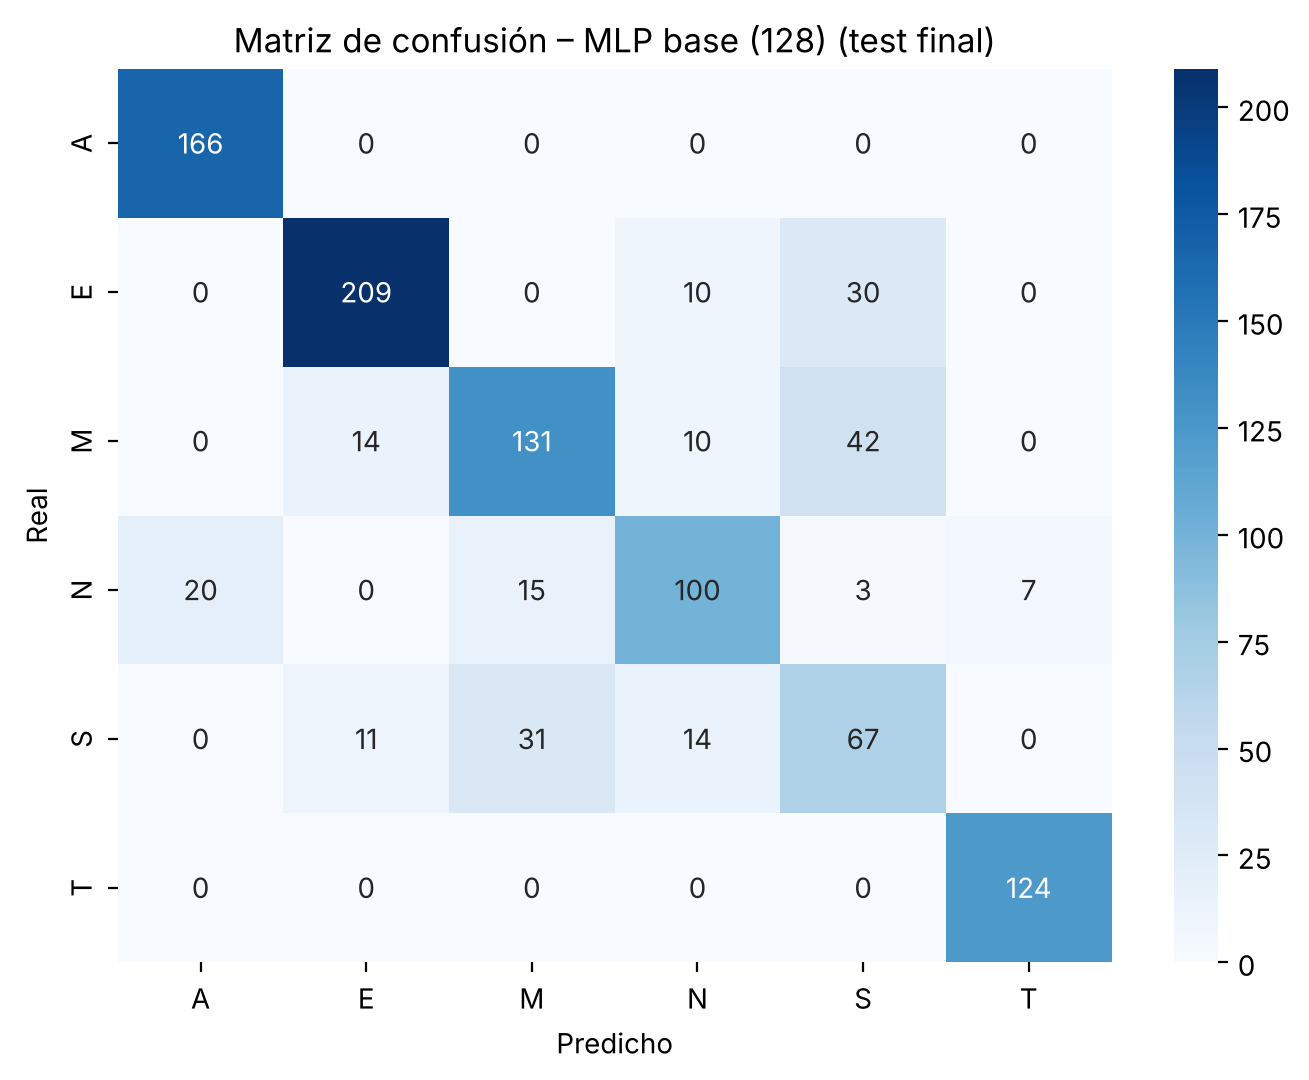

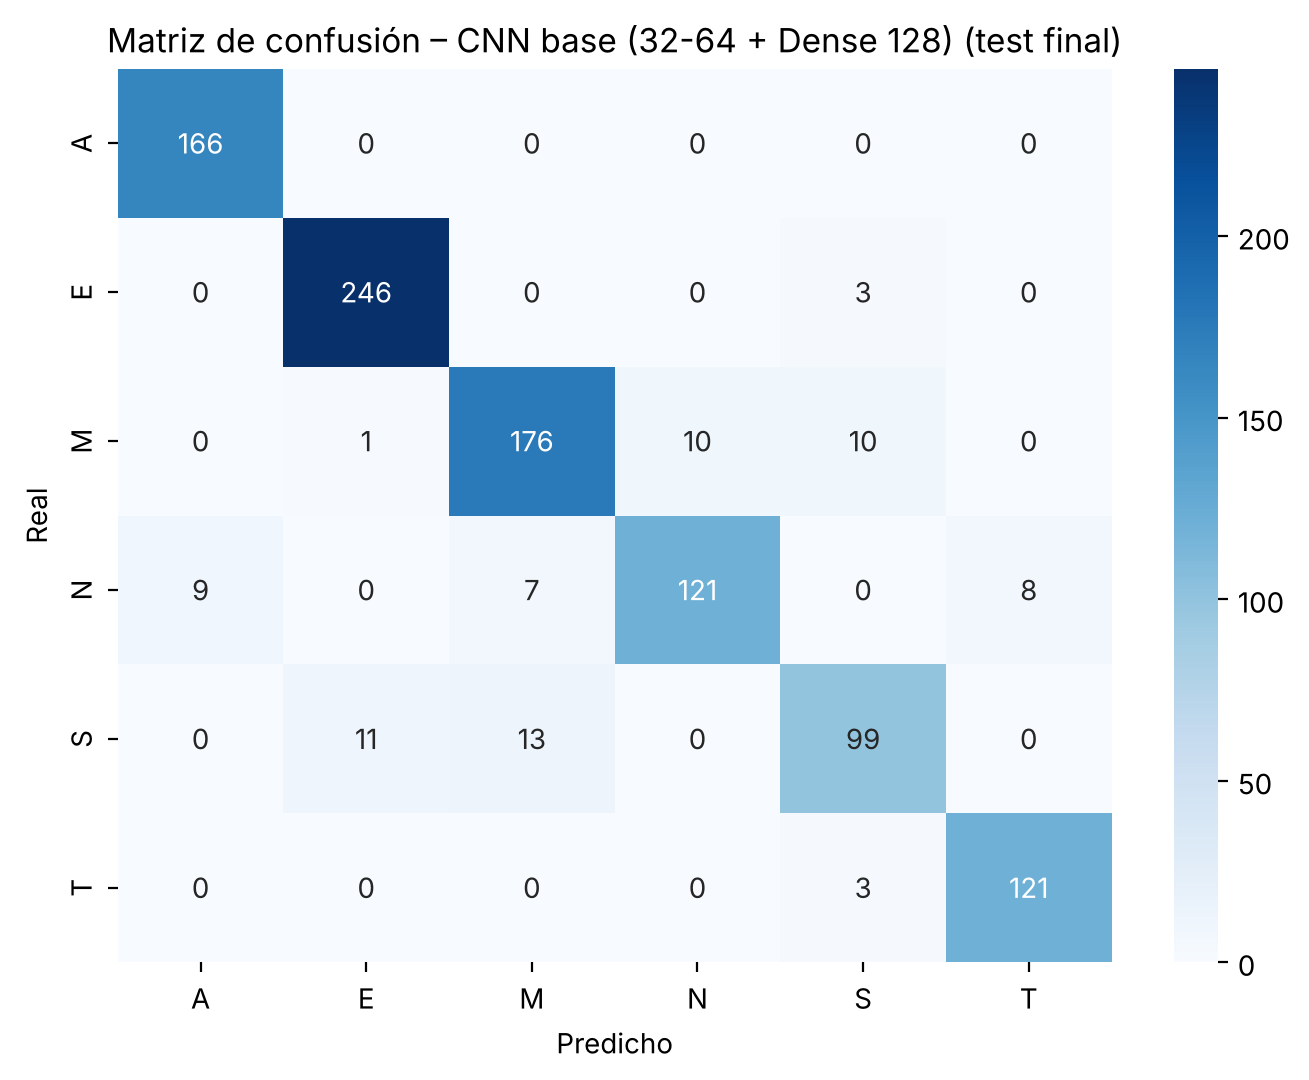

In [11]:
y_test = data['test']['y_int']
for nombre, r in baselines.items():
    print(f"=== {nombre} ===")
    print(classification_report(y_test, r['y_pred'], target_names=letras, digits=3))
    top, total = top_confusiones(y_test, r['y_pred'], letras)
    print(f"{total} errores de {len(y_test)} imágenes. Top 5 confusiones (real -> predicho):",
          ', '.join(f"{a}->{b} ({n})" for (a, b), n in top), '\n')

fig_name = {'MLP base (128)': 'mlp', 'CNN base (32-64 + Dense 128)': 'cnn'}
for nombre, r in baselines.items():
    plot_confusion(y_test, r['y_pred'], letras, f'Matriz de confusión – {nombre} (test final)',
                   save_path=f"{CONFIG['paths']['images']}/ep3_matriz_confusion_{fig_name[nombre]}_base.png")

## 7. Regularización (etapa 6)
Las dos líneas base sobreajustan: llegan a ~100% de accuracy en entrenamiento y la brecha train-validación es grande (0,18 en la MLP y 0,07 en la CNN). Se evalúa cuánto reduce cada técnica esa brecha y si mejora la generalización.

**Diseño experimental (controlado):**
- Cada técnica se aplica **sola** sobre la línea base (un cambio a la vez), más una combinación de todas. Misma semilla, mismo split, mismo Early Stopping.
- **Criterio de selección, fijado antes de ver los resultados:** menor `val_loss` en validación (desempate: mayor `val_acc`). El test final **no** participa en la selección, solo se reporta.
- Un solo valor por técnica en este paso (`dropout=0,3`, `l2=1e-4`, augmentation moderado). La búsqueda de los valores óptimos corresponde al paso de optimización de hiperparámetros.

| Técnica | Cómo ataca el sobreajuste | MLP | CNN |
|---|---|---|---|
| Early Stopping | Detiene el entrenamiento cuando `val_loss` deja de mejorar | ✔ (ya en la base) | ✔ (ya en la base) |
| Dropout | Apaga neuronas al azar: evita que la red dependa de unidades específicas | ✔ | ✔ |
| Regularización L2 | Penaliza pesos grandes: modelos más suaves | ✔ | ✔ |
| Batch Normalization | Normaliza activaciones por lote: entrenamiento más estable y efecto regularizador leve | ✔ | ✔ |
| Data Augmentation | Traslación, rotación y zoom leves en línea: más variedad de posiciones | ✘ | ✔ |

La augmentation se aplica **solo en la CNN**: la MLP aplana la imagen y pierde la estructura espacial, así que las transformaciones geométricas aportan poco ahí. Además, ataca justo la debilidad que la EP2 midió en la CNN: su falta de robustez a la traslación. No se usa volteo horizontal porque espejaría la mano y cambiaría la seña.

### 7.1 Experimentos

In [12]:
DROPOUT, L2 = 0.3, 1e-4
AUG = dict(translation=0.1, rotation=0.05, zoom=0.1)   # ±10% de desplazamiento, ±~9° de rotación, ±10% de zoom

EXPERIMENTOS = {
    'mlp': [
        ('MLP + Dropout',            dict(dropout=DROPOUT)),
        ('MLP + L2',                 dict(l2=L2)),
        ('MLP + BatchNorm',          dict(batch_norm=True)),
        ('MLP + Dropout + L2 + BN',  dict(dropout=DROPOUT, l2=L2, batch_norm=True)),
    ],
    'cnn': [
        ('CNN + Dropout',                  dict(dropout=DROPOUT)),
        ('CNN + L2',                       dict(l2=L2)),
        ('CNN + BatchNorm',                dict(batch_norm=True)),
        ('CNN + Augmentation',             dict(augment=AUG)),
        ('CNN + Dropout + L2 + BN',        dict(dropout=DROPOUT, l2=L2, batch_norm=True)),
        ('CNN + Dropout + L2 + BN + Aug',  dict(dropout=DROPOUT, l2=L2, batch_norm=True, augment=AUG)),
    ],
}
BASE_NAME = {'mlp': 'MLP base (128)', 'cnn': 'CNN base (32-64 + Dense 128)'}
BASE_PARAMS = {'mlp': MLP_BASE, 'cnn': CNN_BASE}

reg_results = {}
for kind in ['mlp', 'cnn']:
    reg_results[kind] = {BASE_NAME[kind]: baselines[BASE_NAME[kind]]}     # la línea base ya se ejecutó
    for nombre, cambios in EXPERIMENTOS[kind]:
        reg_results[kind][nombre] = run_experiment(nombre, kind, {**BASE_PARAMS[kind], **cambios}, data, CONFIG)
        r = reg_results[kind][nombre]
        print(f"{nombre:32s} épocas={len(r['history'].history['loss']):2d} | val_acc={r['val']['accuracy']:.3f} | {r['tiempo']:.0f} s")

MLP + Dropout                    épocas=19 | val_acc=0.809 | 10 s


MLP + L2                         épocas=18 | val_acc=0.810 | 10 s


MLP + BatchNorm                  épocas= 8 | val_acc=0.833 | 4 s


MLP + Dropout + L2 + BN          épocas=10 | val_acc=0.772 | 6 s


CNN + Dropout                    épocas= 8 | val_acc=0.894 | 29 s


CNN + L2                         épocas= 9 | val_acc=0.930 | 34 s


CNN + BatchNorm                  épocas=12 | val_acc=0.945 | 62 s


CNN + Augmentation               épocas=30 | val_acc=0.992 | 144 s


CNN + Dropout + L2 + BN          épocas=13 | val_acc=0.938 | 68 s


CNN + Dropout + L2 + BN + Aug    épocas=30 | val_acc=1.000 | 160 s


### 7.2 Resultados comparativos
`Δ Val Loss` es la diferencia contra la línea base de la misma arquitectura (negativo = mejora). La brecha es `train_acc − val_acc` en la época elegida.

In [13]:
COLUMNAS = ['Épocas', 'Tiempo (s)', 'Val Loss', 'Δ Val Loss', 'Val Acc', 'Train Acc', 'Brecha train-val',
            'Test Acc', 'Test F1', 'Test ROC-AUC']


def tabla_regularizacion(results, base_name):
    """Tabla comparativa de un conjunto de experimentos, con la diferencia de val_loss contra la línea base."""
    df = pd.DataFrame([summarize_run(r) for r in results.values()]).set_index('Modelo')
    df['Δ Val Loss'] = (df['Val Loss'] - df.loc[base_name, 'Val Loss']).round(3)
    return df[COLUMNAS]


def elegir_mejor(results):
    """Criterio fijado de antemano: menor val_loss (desempate: mayor val_acc). No usa el test."""
    return min(results.values(), key=lambda r: (min(r['history'].history['val_loss']), -r['val']['accuracy']))['name']


tablas = {k: tabla_regularizacion(reg_results[k], BASE_NAME[k]) for k in reg_results}
for k, t in tablas.items():
    print(f"\n=== {k.upper()} ===")
    display(t)
    t.to_csv(f"{CONFIG['paths']['images']}/ep3_regularizacion_{k}_tabla.csv")


=== MLP ===


,Épocas,Tiempo (s),Val Loss,Δ Val Loss,Val Acc,Train Acc,Brecha train-val,Test Acc,Test F1,Test ROC-AUC
Modelo,,,,,,,,,,
MLP base (128),18,7.5,0.574,0.000,0.811,0.993,0.182,0.794,0.784,0.950
MLP + Dropout,19,10.1,0.553,-0.021,0.809,0.939,0.130,0.775,0.761,0.949
MLP + L2,18,9.8,0.599,0.025,0.810,0.994,0.184,0.789,0.779,0.949
MLP + BatchNorm,8,4.0,0.552,-0.022,0.833,1.000,0.167,0.811,0.798,0.964
MLP + Dropout + L2 + BN,10,6.5,0.739,0.165,0.772,1.000,0.228,0.780,0.760,0.940



=== CNN ===


,Épocas,Tiempo (s),Val Loss,Δ Val Loss,Val Acc,Train Acc,Brecha train-val,Test Acc,Test F1,Test ROC-AUC
Modelo,,,,,,,,,,
CNN base (32-64 + Dense 128),9,39.6,0.277,0.000,0.926,1.000,0.073,0.925,0.917,0.992
CNN + Dropout,8,29.2,0.275,-0.002,0.894,0.967,0.073,0.892,0.890,0.991
CNN + L2,9,34.2,0.268,-0.009,0.930,1.000,0.070,0.932,0.926,0.994
CNN + BatchNorm,12,62.5,0.240,-0.037,0.945,1.000,0.055,0.941,0.938,0.994
CNN + Augmentation,30,144.3,0.022,-0.255,0.992,0.990,-0.002,0.991,0.991,1.000
CNN + Dropout + L2 + BN,13,67.9,0.221,-0.056,0.938,1.000,0.061,0.954,0.950,0.997
CNN + Dropout + L2 + BN + Aug,30,159.9,0.027,-0.250,1.000,0.936,-0.064,1.000,1.000,1.000


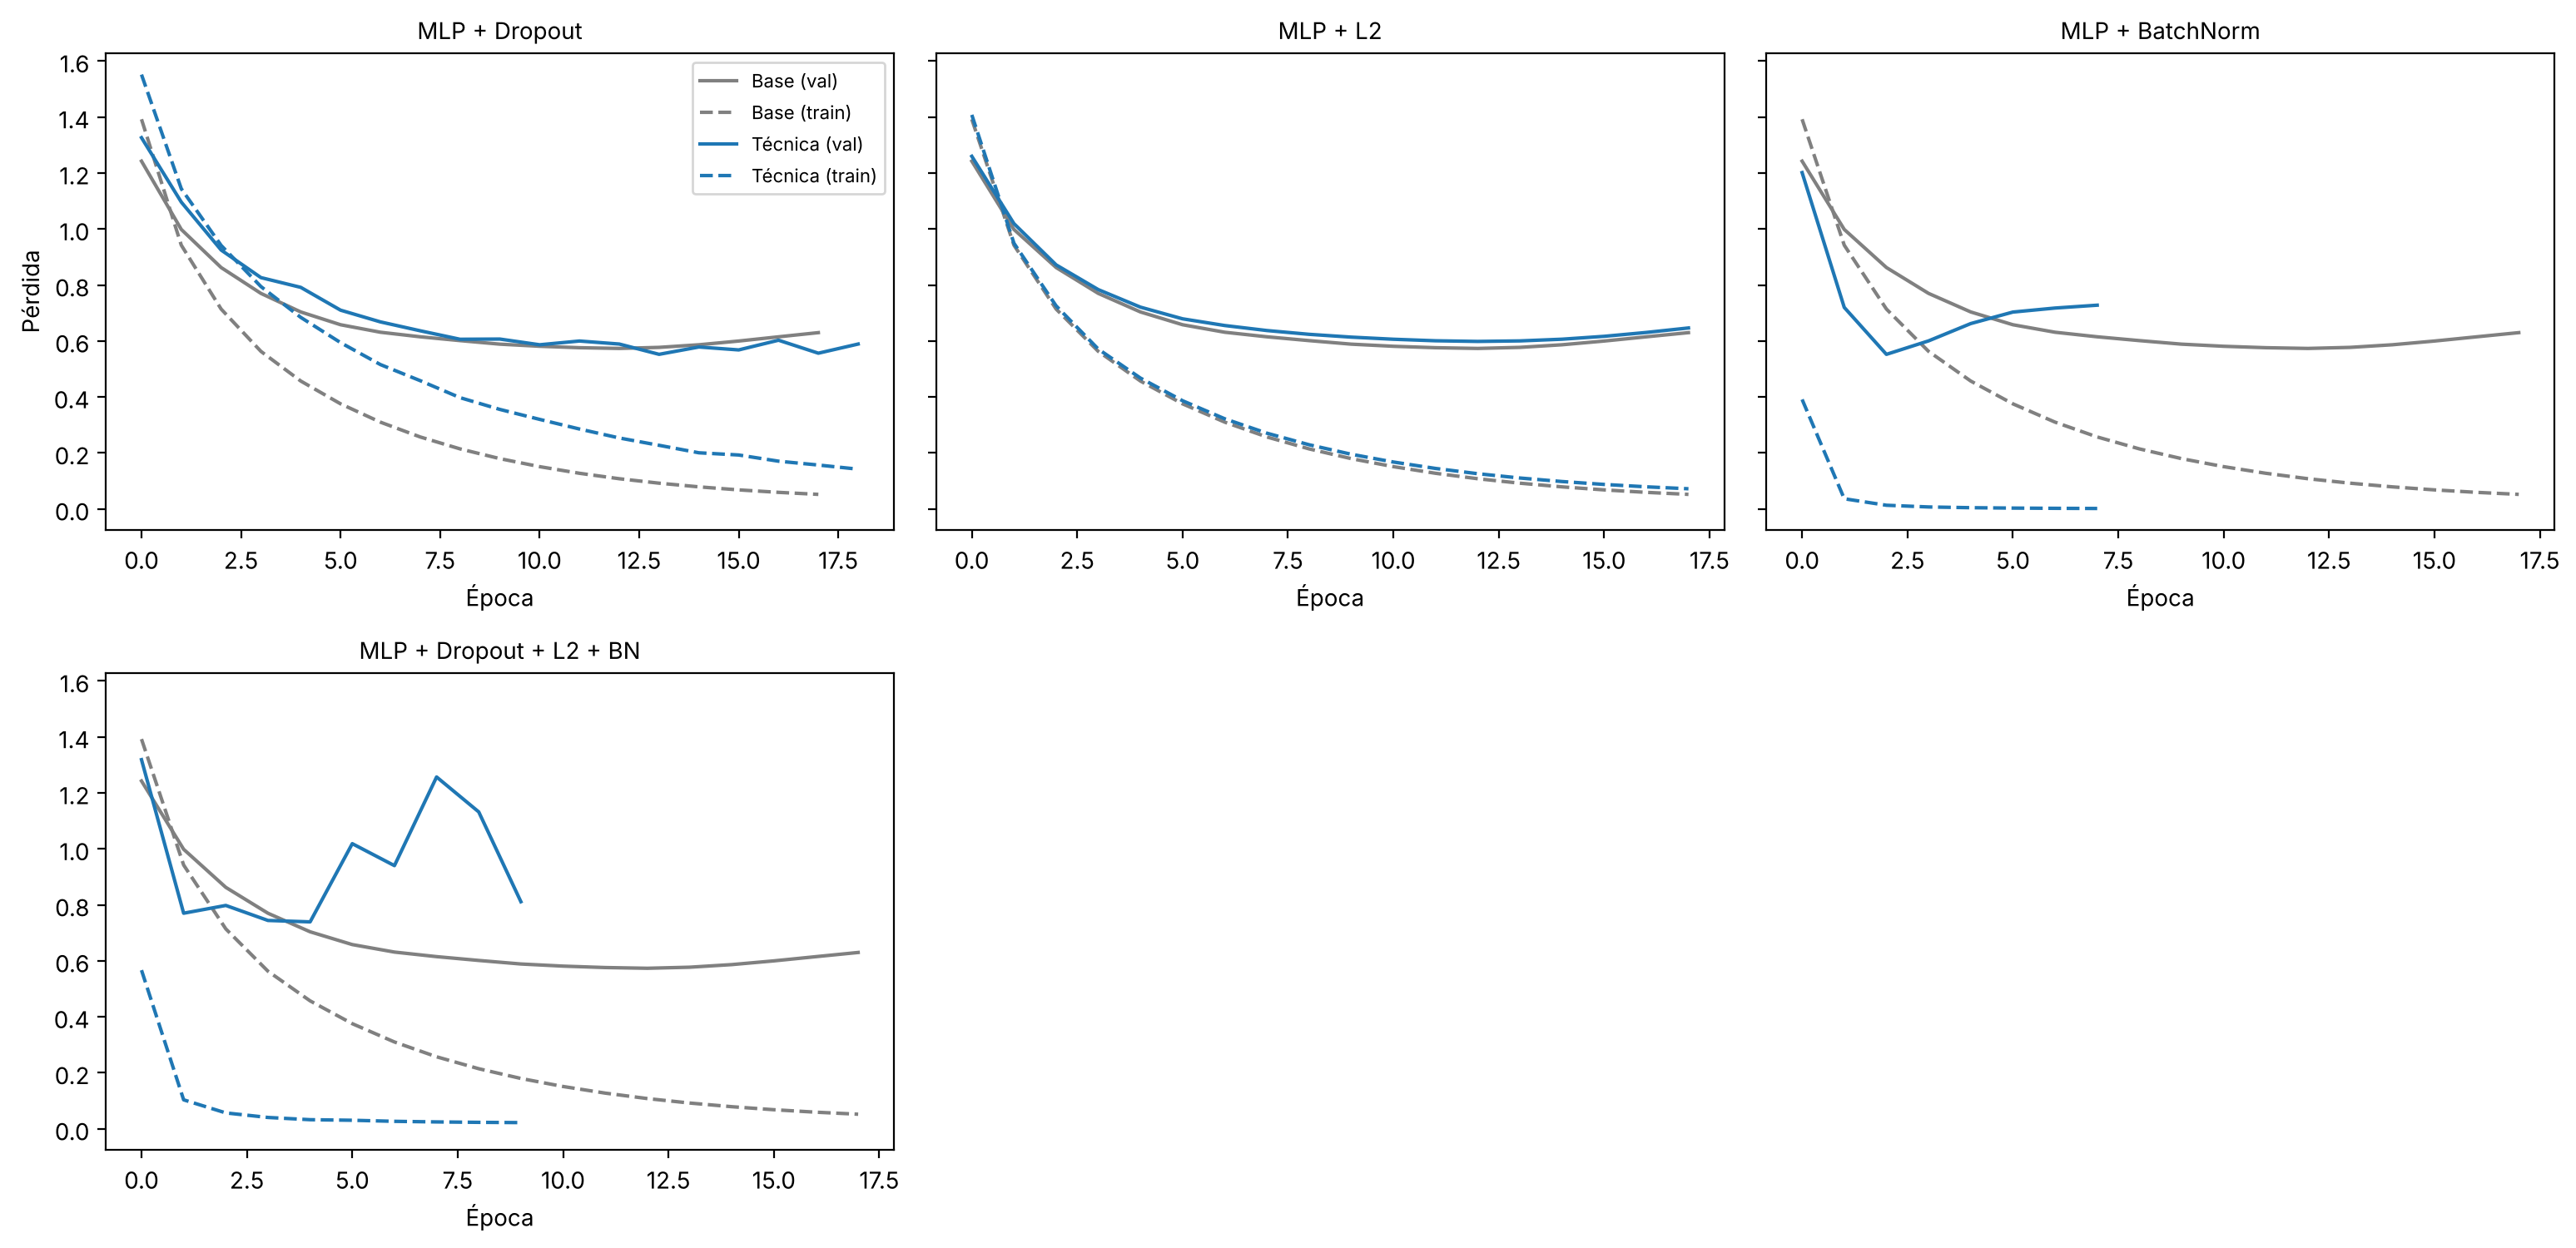

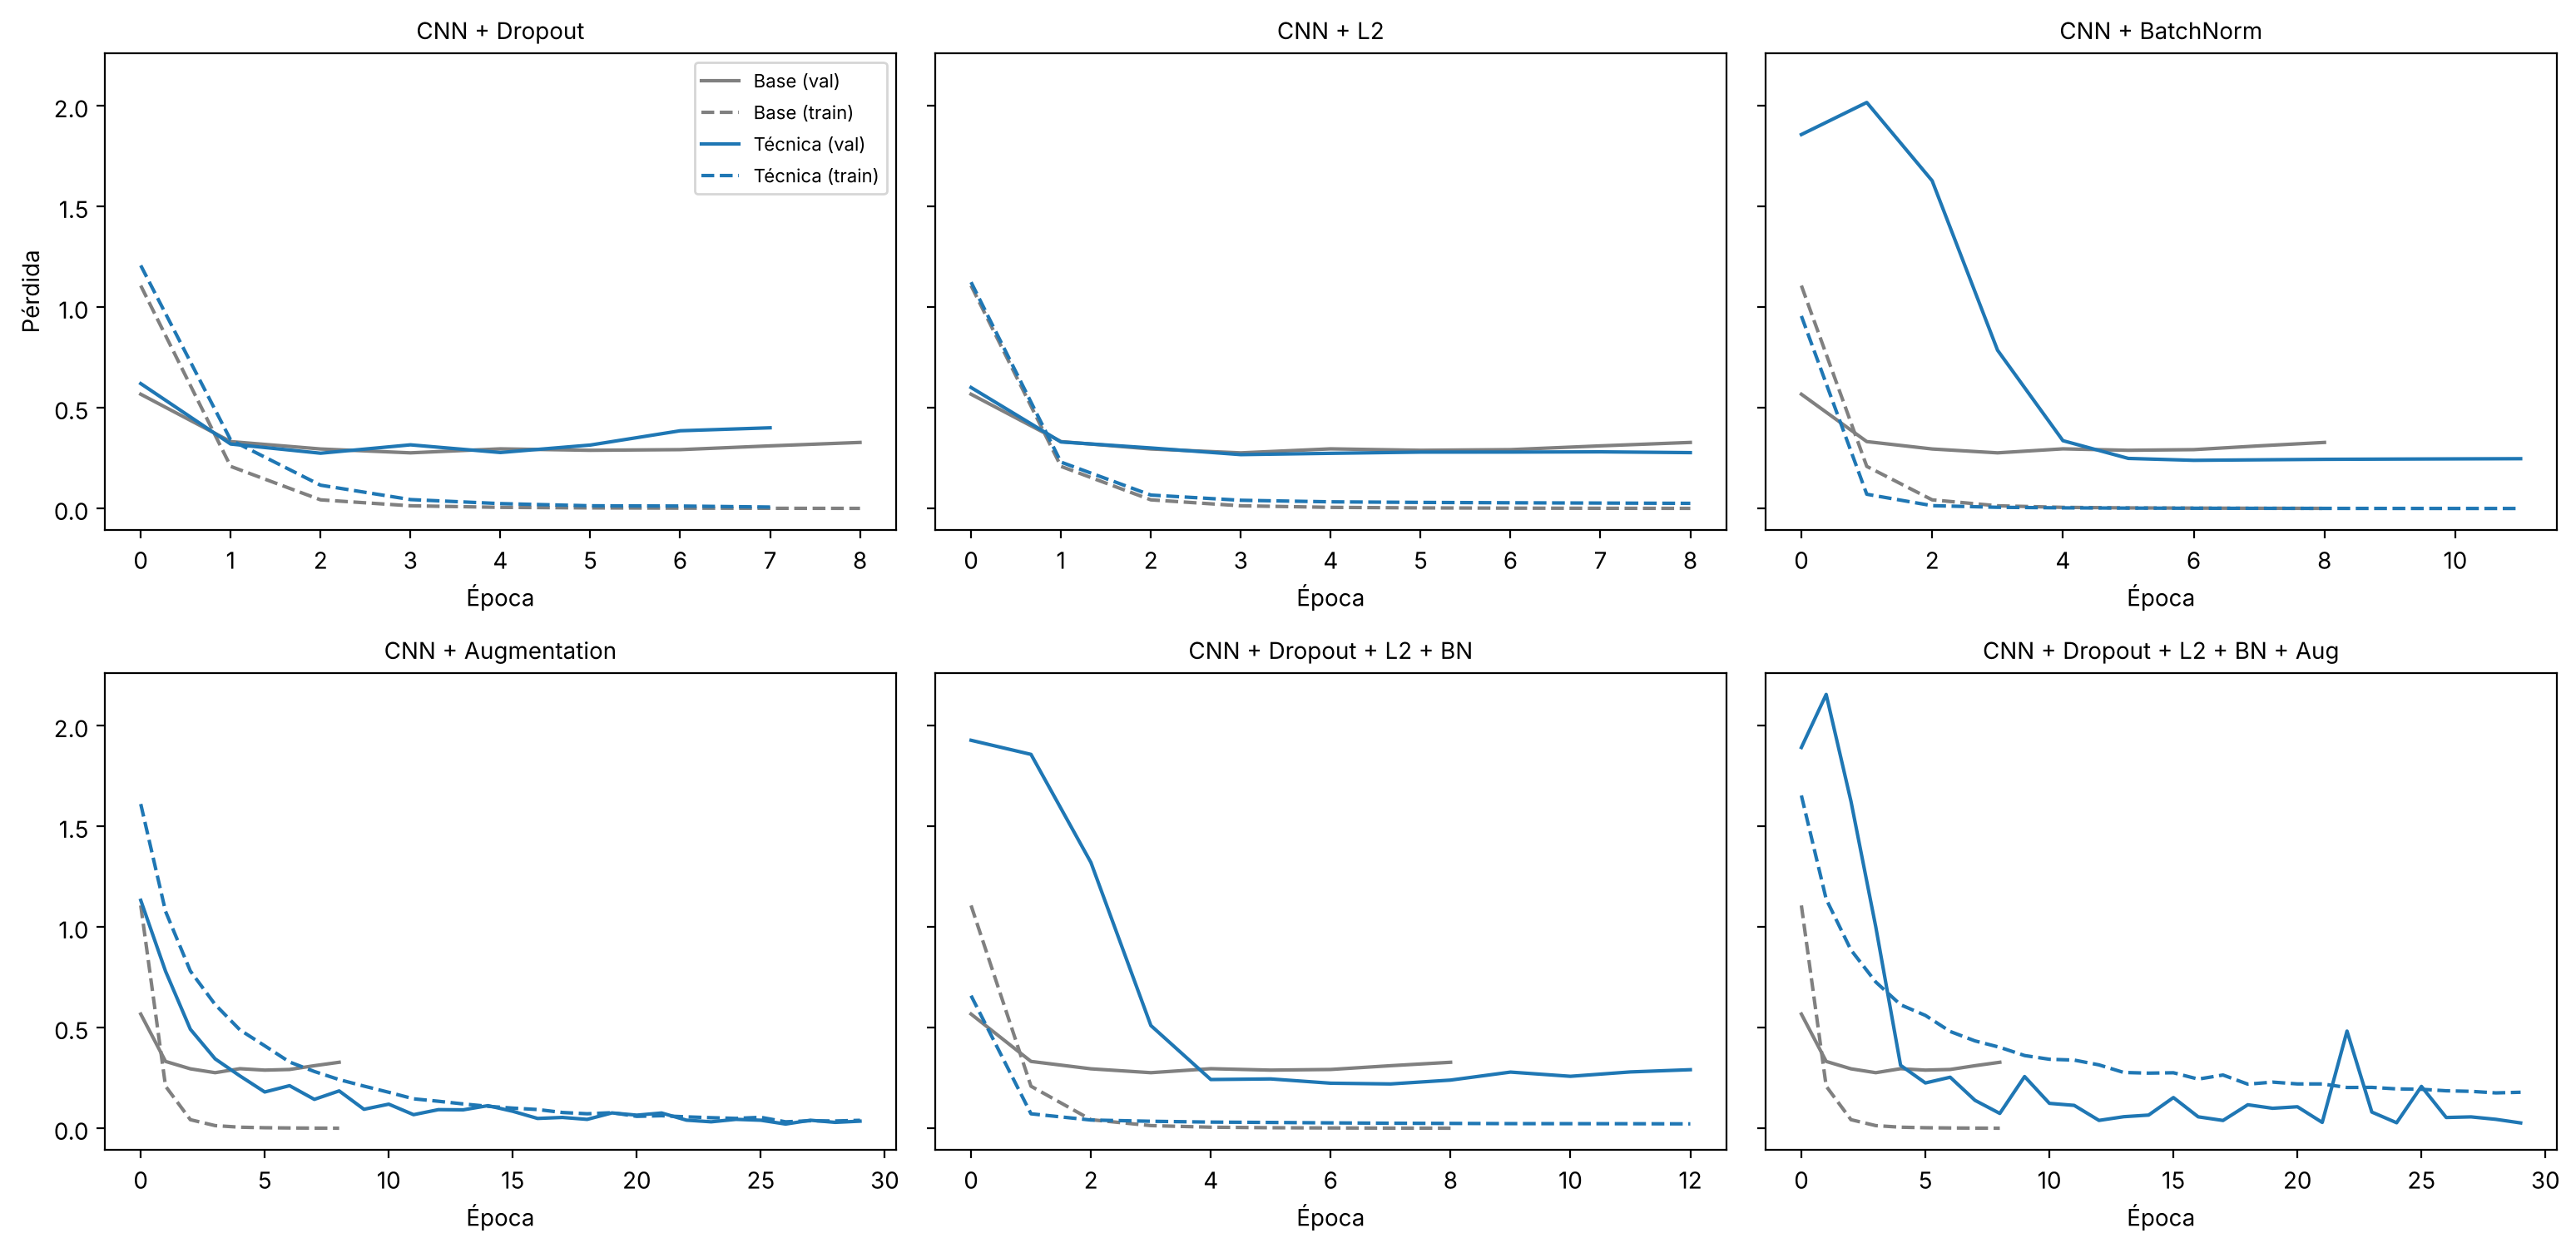

In [14]:
def plot_regularizacion(results, base_name, save_path=None, ncols=3):
    """Una figura por arquitectura: en cada panel, la línea base (gris) contra una técnica (color).
    Línea continua = validación, punteada = entrenamiento. La brecha entre ambas es el sobreajuste."""
    runs = [r for n, r in results.items() if n != base_name]
    nrows = int(np.ceil(len(runs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.8 * nrows), sharey=True, squeeze=False)
    hb = results[base_name]['history'].history
    for ax, r in zip(axes.ravel(), runs):
        h = r['history'].history
        ax.plot(hb['val_loss'], color='gray', label='Base (val)')
        ax.plot(hb['loss'], color='gray', linestyle='--', label='Base (train)')
        ax.plot(h['val_loss'], color='tab:blue', label='Técnica (val)')
        ax.plot(h['loss'], color='tab:blue', linestyle='--', label='Técnica (train)')
        ax.set_title(r['name'], fontsize=10); ax.set_xlabel('Época')
    for ax in axes.ravel()[len(runs):]:
        ax.axis('off')
    axes[0, 0].set_ylabel('Pérdida'); axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()


for k in ['mlp', 'cnn']:
    plot_regularizacion(reg_results[k], BASE_NAME[k], save_path=f"{CONFIG['paths']['images']}/ep3_regularizacion_{k}_curvas.png")

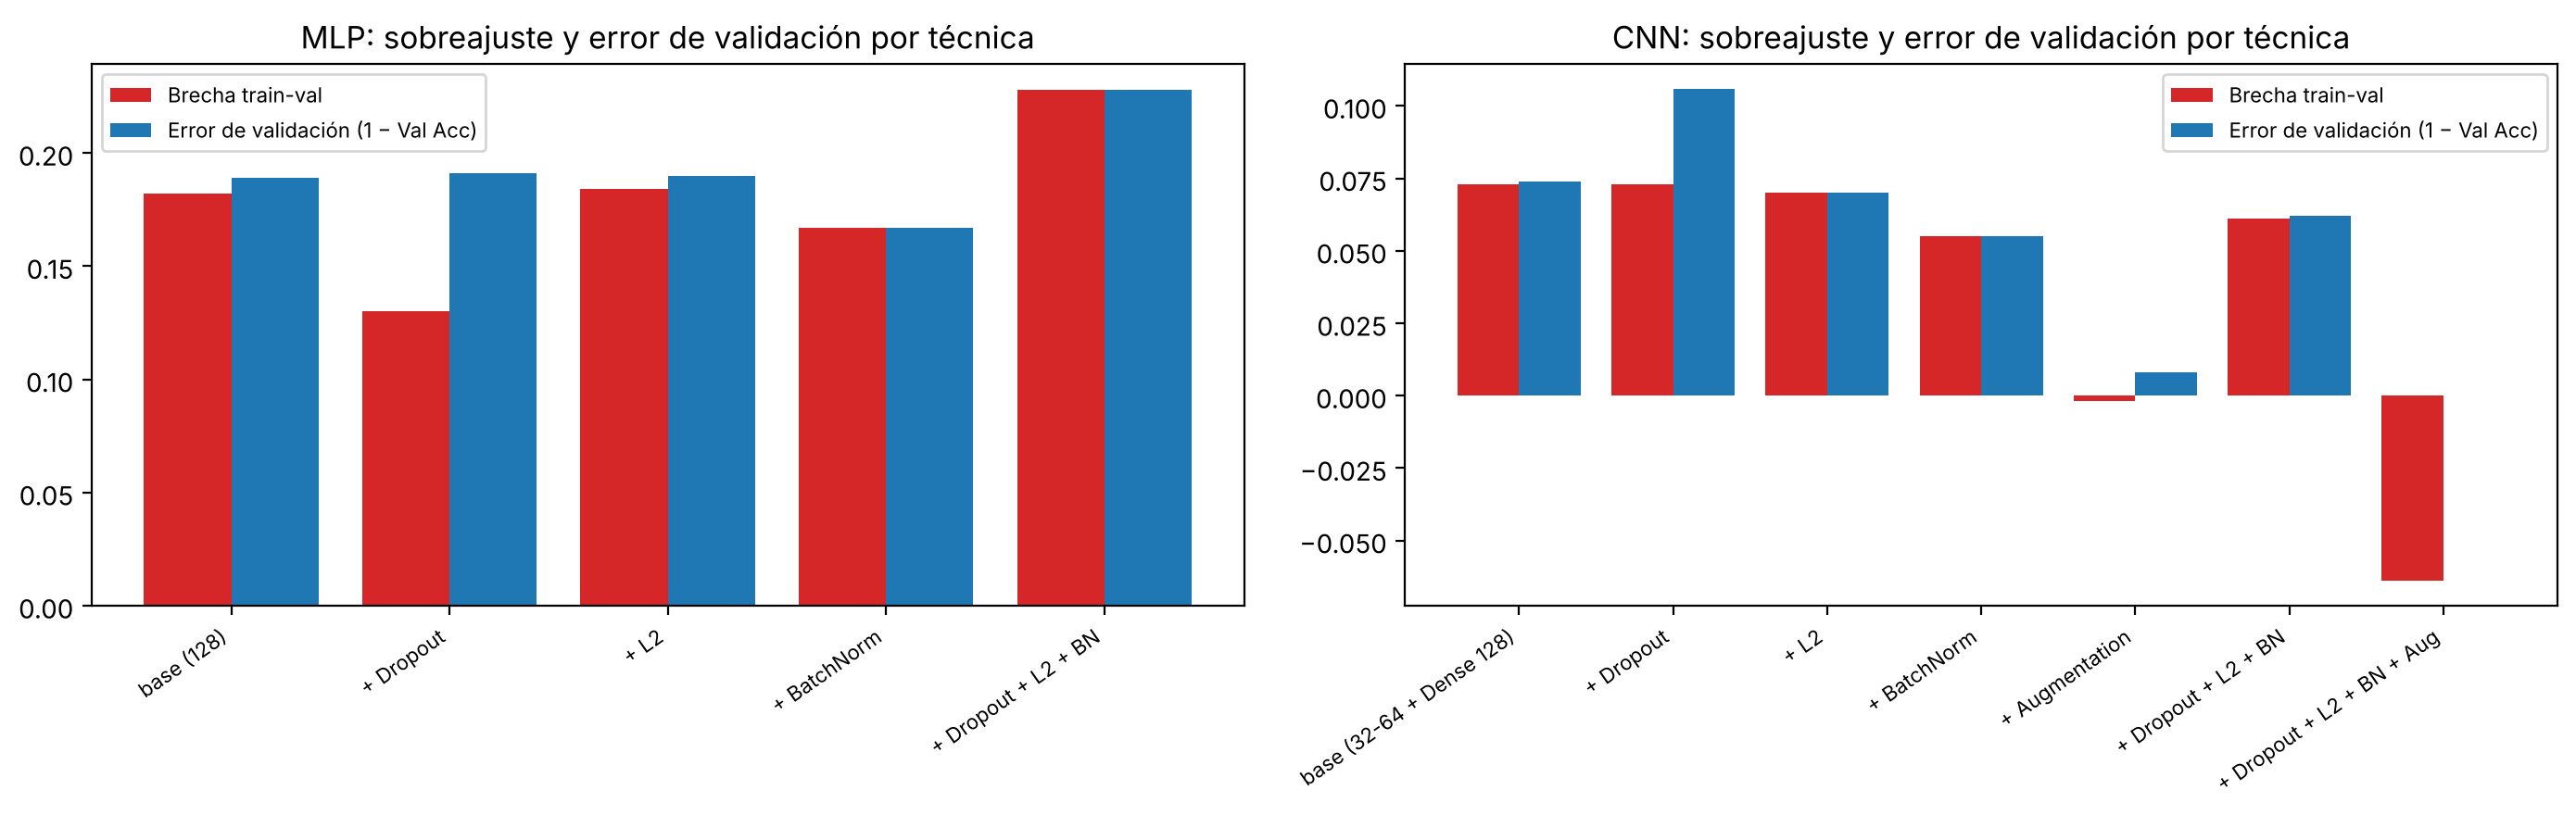

Mejor configuración MLP según val_loss: MLP + BatchNorm
Mejor configuración CNN según val_loss: CNN + Augmentation


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, k, titulo in [(axes[0], 'mlp', 'MLP'), (axes[1], 'cnn', 'CNN')]:
    t = tablas[k]
    x = np.arange(len(t))
    ax.bar(x - 0.2, t['Brecha train-val'], 0.4, label='Brecha train-val', color='tab:red')
    ax.bar(x + 0.2, 1 - t['Val Acc'], 0.4, label='Error de validación (1 − Val Acc)', color='tab:blue')
    ax.set_xticks(x); ax.set_xticklabels([n.replace(f'{titulo} ', '').replace(' base (128)', 'base').replace(' base (32-64 + Dense 128)', 'base')
                                          for n in t.index], rotation=35, ha='right', fontsize=8)
    ax.set_title(f'{titulo}: sobreajuste y error de validación por técnica'); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{CONFIG['paths']['images']}/ep3_regularizacion_resumen.png")
plt.show()

MEJOR = {k: elegir_mejor(reg_results[k]) for k in reg_results}
for k, nombre in MEJOR.items():
    print(f"Mejor configuración {k.upper()} según val_loss: {nombre}")

### 7.2b Lectura de los resultados
**MLP**
- **Dropout (0,3)** reduce la brecha train-validación (0,182 → 0,130), pero el accuracy de validación no mejora (0,809 vs 0,811): memoriza menos, pero no generaliza mejor.
- **L2 (1e-4)** casi no cambia nada (Δ val_loss +0,025, dentro del ruido). Con este valor la penalización es pequeña frente a la pérdida; su magnitud se afina en la optimización.
- **BatchNorm** es la mejor técnica para la MLP: val_loss 0,552, val_acc 0,833, test 0,811 (F1 0,798, ROC-AUC 0,964) y converge en menos de la mitad de épocas (8 vs 18). Aun así sigue sobreajustando (train 1,000).
- **Dropout + L2 + BN juntas empeoran** (val_loss 0,739, val_acc 0,772): las técnicas no se suman automáticamente. Una posible explicación, *no verificada aquí*, es una interacción entre Dropout y BatchNorm.
- Ninguna técnica lleva a la MLP más allá de ~0,81 de accuracy. El límite parece estructural (aplanar la imagen pierde la información espacial), no de falta de regularización.

**CNN**
- **Dropout solo empeora** (val_acc 0,894 vs 0,926). **L2** mejora apenas (0,930, dentro del ruido). **BatchNorm** mejora de forma consistente: val_loss 0,240, val_acc 0,945, test 0,941.
- **Data Augmentation es, por amplio margen, la técnica de mayor impacto:** val_loss 0,277 → 0,022, val_acc 0,992, brecha ≈ 0 y test 0,991 (F1 0,991). A cambio, el entrenamiento es ~4 veces más lento (144 s vs 37 s).
- La brecha **negativa** con augmentation no indica subajuste: el accuracy de entrenamiento se mide sobre imágenes ya transformadas (más difíciles), mientras validación y test no se transforman.
- **Combinación completa (Dropout + L2 + BN + Aug):** val_acc 1,000 y test 1,000, pero con val_loss 0,027 > 0,022 de la augmentation sola. Con el criterio fijado de antemano (menor val_loss) se elige **`CNN + Augmentation`**. La diferencia entre ambas son unas 8 imágenes de validación, dentro del ruido, así que se prefiere la más simple y se vuelve a compararlas en la optimización.

**Selección para el paso siguiente (según `val_loss`):** `MLP + BatchNorm` y `CNN + Augmentation`.

**Limitaciones que hay que tener presentes**
- Las dos configuraciones con augmentation llegaron a las **30 épocas sin que Early Stopping se activara**: la pérdida seguía bajando, así que el tope de épocas puede estar limitando el resultado.
- Validación y test salen del **mismo archivo de test**, con las mismas manos. Un 100% en test no demuestra generalización a personas nuevas. Esto se discute en la auditoría de sesgos.
- Es **una sola semilla**: con ~1.000 imágenes de validación, diferencias de ~1 punto de accuracy están dentro del ruido (error estándar ≈ 1 punto).

### 7.3 Efecto de Early Stopping
Early Stopping ya está en todos los experimentos anteriores. Para medir su aporte se entrena cada línea base **sin él** (30 épocas completas) y se compara el modelo final contra el de la mejor época.

,Épocas,Época elegida,Tiempo (s),Val Loss,Val Acc,Brecha train-val,Test Acc,Test F1
Modelo,,,,,,,,
MLP base (128),18,13,7.5,0.574,0.811,0.182,0.794,0.784
MLP base sin Early Stopping,30,30,13.1,0.743,0.817,0.183,0.811,0.797
CNN base (32-64 + Dense 128),9,4,39.6,0.277,0.926,0.073,0.925,0.917
CNN base sin Early Stopping,30,30,105.6,0.385,0.916,0.084,0.925,0.918


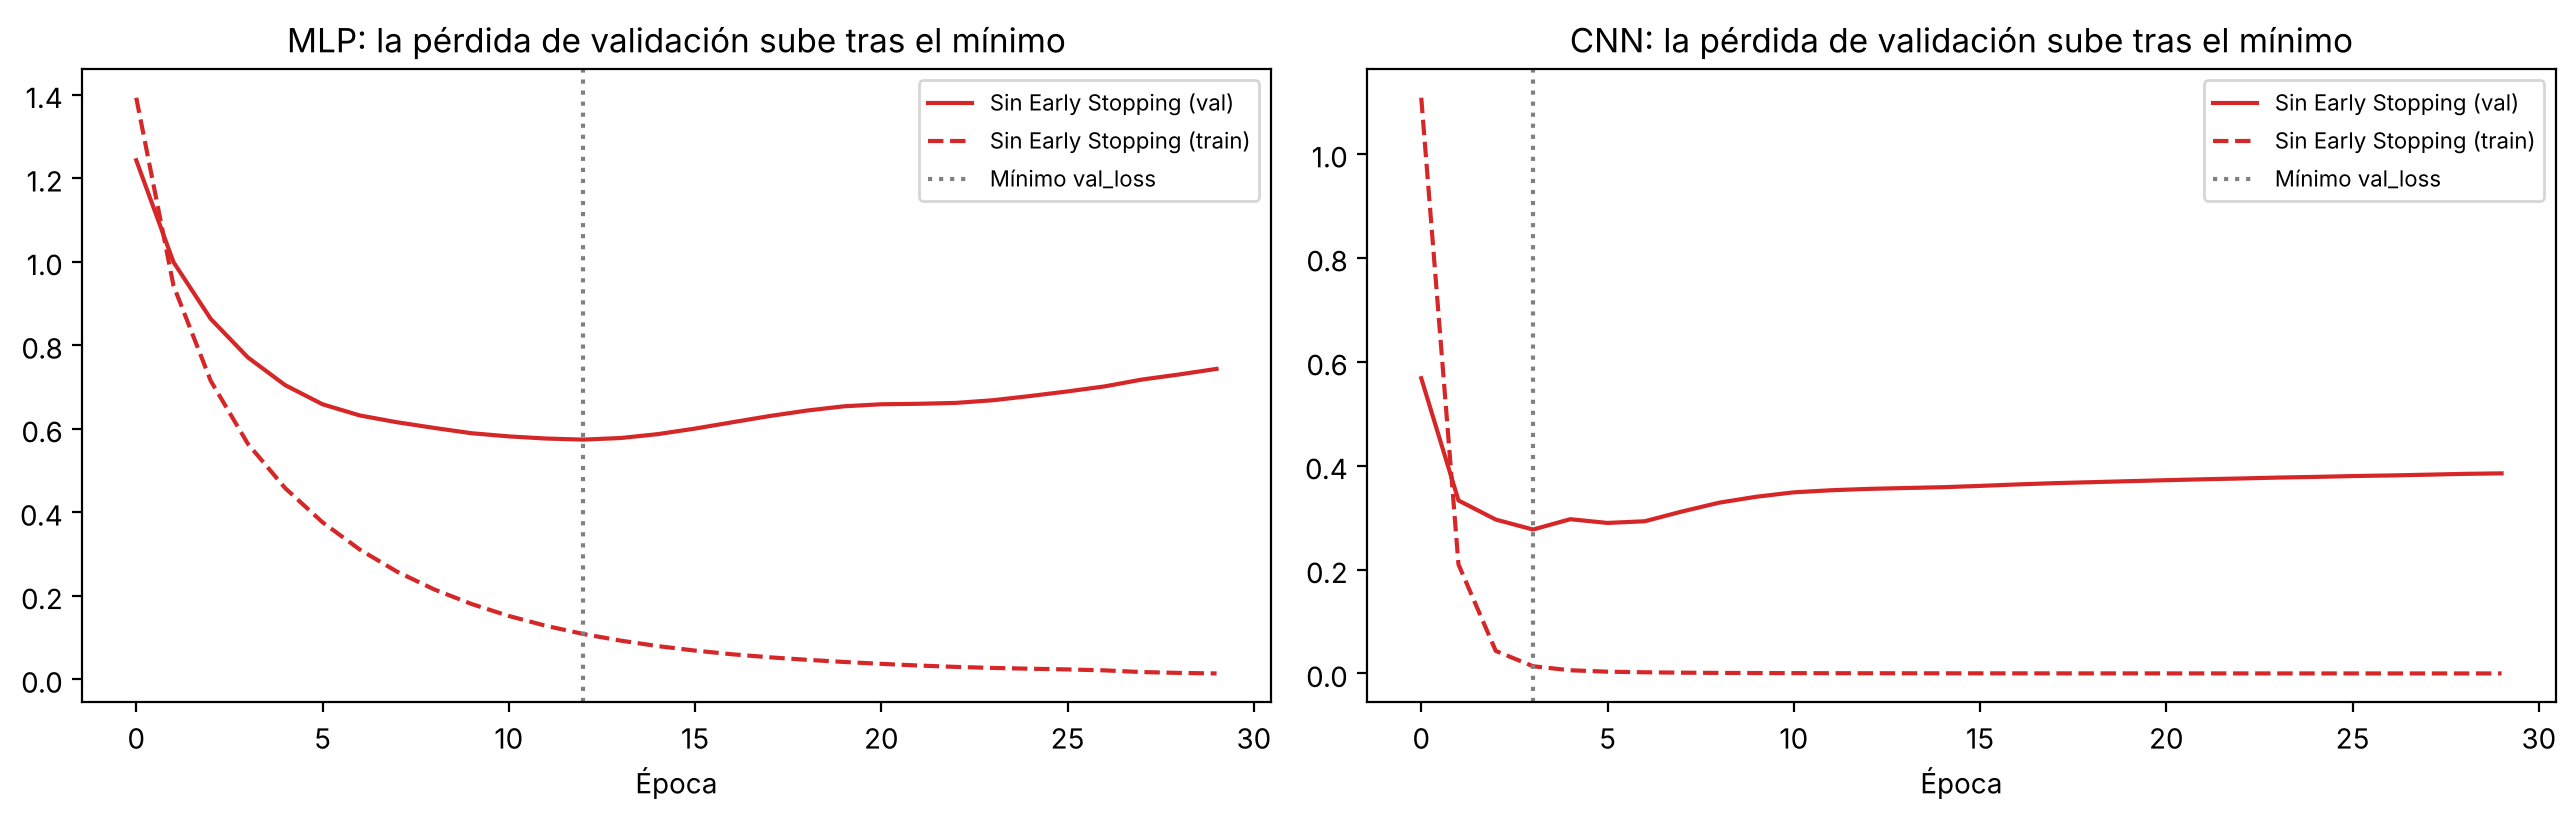

In [16]:
CONFIG_SIN_ES = {**CONFIG, 'early_stopping': False}
sin_es = {
    'mlp': run_experiment('MLP base sin Early Stopping', 'mlp', MLP_BASE, data, CONFIG_SIN_ES),
    'cnn': run_experiment('CNN base sin Early Stopping', 'cnn', CNN_BASE, data, CONFIG_SIN_ES),
}
filas = [summarize_run(r) for k in ['mlp', 'cnn'] for r in (baselines[BASE_NAME[k]], sin_es[k])]
df_es = pd.DataFrame(filas).set_index('Modelo')[['Épocas', 'Época elegida', 'Tiempo (s)', 'Val Loss', 'Val Acc',
                                                  'Brecha train-val', 'Test Acc', 'Test F1']]
display(df_es)
df_es.to_csv(f"{CONFIG['paths']['images']}/ep3_early_stopping_tabla.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, k, titulo in [(axes[0], 'mlp', 'MLP'), (axes[1], 'cnn', 'CNN')]:
    h_es, h_no = baselines[BASE_NAME[k]]['history'].history, sin_es[k]['history'].history
    ax.plot(h_no['val_loss'], color='tab:red', label='Sin Early Stopping (val)')
    ax.plot(h_no['loss'], color='tab:red', linestyle='--', label='Sin Early Stopping (train)')
    ax.axvline(int(np.argmin(h_no['val_loss'])), color='gray', linestyle=':', label='Mínimo val_loss')
    ax.set_title(f'{titulo}: la pérdida de validación sube tras el mínimo'); ax.set_xlabel('Época'); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{CONFIG['paths']['images']}/ep3_early_stopping_curvas.png")
plt.show()

**Lectura:** sin Early Stopping la pérdida de validación sube después de su mínimo (MLP: 0,574 → 0,743; CNN: 0,277 → 0,385), es decir, el modelo se vuelve sobreconfiado. Sin embargo, el **accuracy no empeora**: MLP 0,794 con Early Stopping vs 0,811 sin él, y CNN 0,925 en ambos casos. En estos datos, Early Stopping aporta sobre todo **mejor pérdida y menor costo** (la CNN entrena en ~37 s en vez de ~129 s, 3,5 veces menos), no más accuracy. Se mantiene en el pipeline porque el criterio de selección es `val_loss` y porque ahorra cómputo.

### 7.4 Robustez a la traslación
La EP2 mostró que la CNN base pierde mucho accuracy cuando la imagen se desplaza horizontalmente. Se repite aquí el mismo experimento (`np.roll` sobre el test final, igual que en la EP2) para ver si la augmentation, y las demás técnicas, cambian esa robustez. Es un diagnóstico sobre el test final; **no** se usa para seleccionar.

,0 px,1 px,2 px,4 px
Modelo,,,,
MLP base (128),0.794,0.637,0.421,0.209
MLP + BatchNorm,0.811,0.708,0.519,0.241
CNN base (32-64 + Dense 128),0.925,0.808,0.561,0.242
CNN + Augmentation,0.991,0.957,0.951,0.707


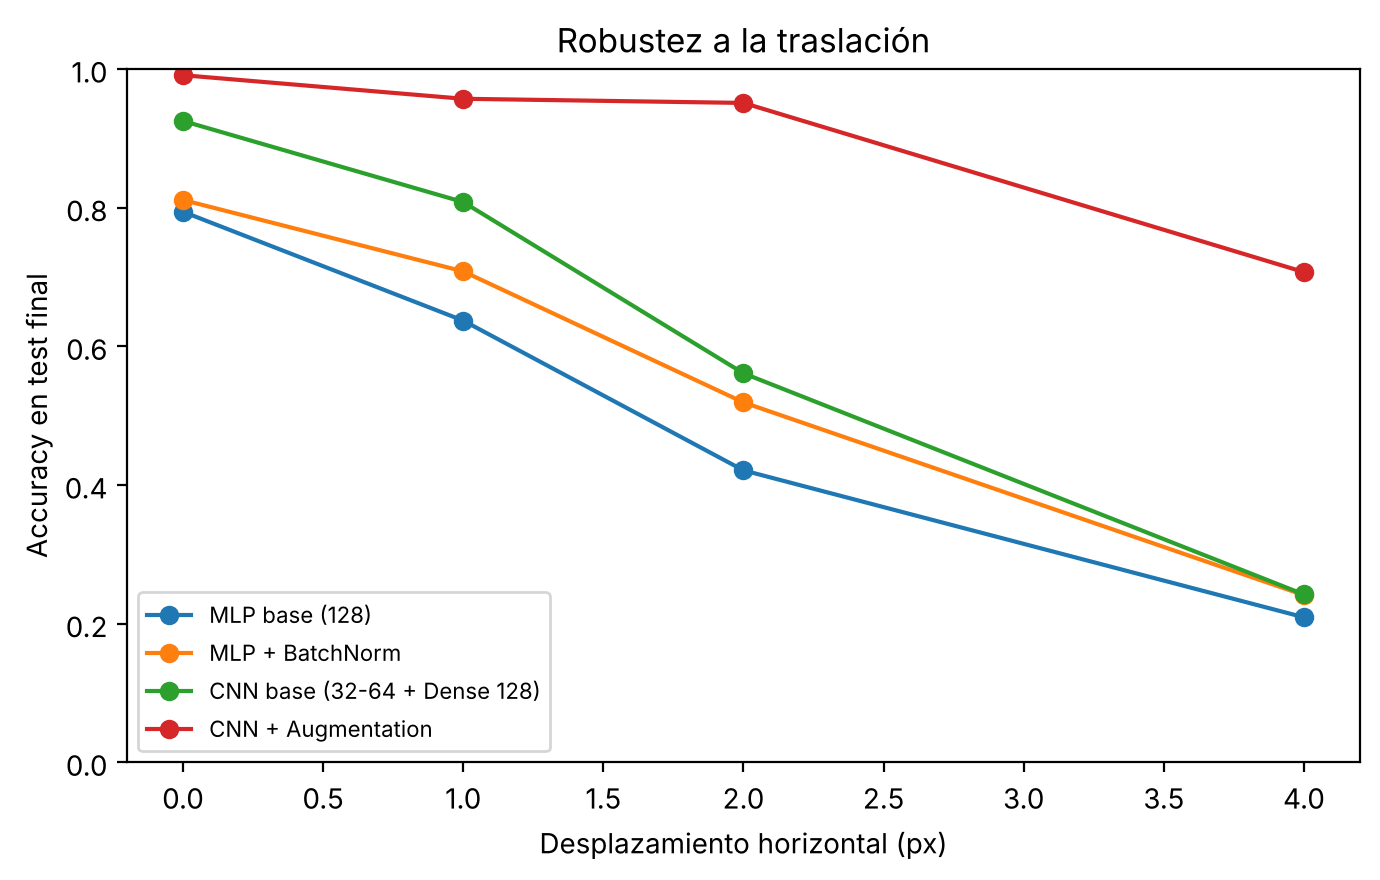

In [17]:
def translation_robustness(results, data, shifts=(0, 1, 2, 4)):
    """Accuracy en test final al desplazar las imágenes horizontalmente (np.roll, igual que en la EP2)."""
    filas = []
    for r in results:
        fila = {'Modelo': r['name']}
        for sh in shifts:
            Xs = np.roll(data['test']['img'], shift=sh, axis=2)
            Xin = Xs if r['kind'] == 'cnn' else Xs.reshape(-1, 784)
            pred = np.argmax(r['model'].predict(Xin, verbose=0), axis=1)
            fila[f'{sh} px'] = round(accuracy_score(data['test']['y_int'], pred), 3)
        filas.append(fila)
    return pd.DataFrame(filas).set_index('Modelo')


candidatos = [reg_results['mlp'][BASE_NAME['mlp']], reg_results['mlp'][MEJOR['mlp']],
              reg_results['cnn'][BASE_NAME['cnn']], reg_results['cnn']['CNN + Augmentation'],
              reg_results['cnn'][MEJOR['cnn']]]
candidatos = list({r['name']: r for r in candidatos}.values())    # sin repetidos (la mejor config puede coincidir con otra)
df_trasl = translation_robustness(candidatos, data)
display(df_trasl)
df_trasl.to_csv(f"{CONFIG['paths']['images']}/ep3_traslacion_tabla.csv")

plt.figure(figsize=(7, 4.5))
for nombre, fila in df_trasl.iterrows():
    plt.plot([0, 1, 2, 4], fila.values, marker='o', label=nombre)
plt.xlabel('Desplazamiento horizontal (px)'); plt.ylabel('Accuracy en test final'); plt.ylim(0, 1)
plt.title('Robustez a la traslación'); plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{CONFIG['paths']['images']}/ep3_traslacion.png")
plt.show()

**Lectura:** la fragilidad a la traslación que midió la EP2 se confirma y se reduce mucho con augmentation.

| Desplazamiento | MLP base | MLP + BN | CNN base | CNN + Aug |
|---|---|---|---|---|
| 0 px | 0,794 | 0,811 | 0,925 | 0,991 |
| 1 px | 0,637 | 0,708 | 0,808 | 0,957 |
| 2 px | 0,421 | 0,519 | 0,561 | 0,951 |
| 4 px | 0,209 | 0,241 | 0,242 | 0,707 |

- La CNN base cae a 0,242 con 4 px, casi igual que la MLP: en la práctica no aprovecha la invarianza a la traslación que la arquitectura permite en teoría.
- Con augmentation, el accuracy a 2 px pasa de 0,561 a 0,951 y a 4 px de 0,242 a 0,707.
- A 4 px baja porque queda **fuera del rango entrenado** (el augmentation mueve hasta ±10% de 28 px ≈ ±2,8 px). Ampliar ese rango es un hiperparámetro a explorar en la optimización.
- Como en la EP2, `np.roll` hace que los píxeles que salen por un borde reaparezcan por el otro, lo que es una perturbación más dura que un desplazamiento real.

---
### Conclusión del paso 2 (regularización)
1. **Se aplicaron y compararon** Early Stopping, Dropout, L2, BatchNorm y Data Augmentation, con curvas de aprendizaje y métricas de validación y test.
2. **MLP:** el mejor resultado es `MLP + BatchNorm` (test 0,811); la regularización mejora poco y el límite parece estructural.
3. **CNN:** el mayor aporte es la **Data Augmentation** (test 0,925 → 0,991), que además es la técnica que mejora la robustez a la traslación.
4. Para el paso de **optimización**, los puntos de partida son `MEJOR['mlp']` y `MEJOR['cnn']`, y quedan pendientes: valores de dropout y L2, magnitud de la augmentation, más épocas para las configuraciones con augmentation y confirmar con varias semillas los candidatos finales.

## 8. Optimización de hiperparámetros (etapa 9)
**Estrategia: Grid Search por factor, un hiperparámetro a la vez** (descenso por coordenadas):
1. **Punto de partida:** la mejor configuración de cada arquitectura según la sección 7 (`MEJOR`).
2. Se recorren los factores en un orden fijo. En cada factor se prueban todos sus valores **dejando el resto en la mejor configuración vigente**; el valor ganador pasa a ser la nueva configuración vigente.
3. **Criterio de selección, fijado antes de ver los resultados:** menor `val_loss` (desempate: mayor `val_acc`). El test final no participa.
4. Al final, la configuración elegida y la de partida se **repiten con 3 semillas** para saber si la mejora es real o está dentro del ruido.

**Por qué este diseño:** un grid completo sería inviable (la CNN tendría 3×2×3×3×3 = 162 entrenamientos y la MLP 5×4×4×3 = 240). La búsqueda por factor cuesta una fracción de eso y cumple con modificar un hiperparámetro a la vez. Su limitación es que **no explora interacciones** entre factores, y el resultado puede depender del orden.

**Espacio de búsqueda** (el orden va de mayor a menor impacto esperado según la sección 7):

| Orden | MLP (parte de `MLP + BatchNorm`) | CNN (parte de `CNN + Augmentation`) |
|---|---|---|
| 1 | `units`: (64), (128), (256), (128, 64), (256, 128) | `aug_translation`: 0,05 · 0,10 · 0,20 |
| 2 | `dropout`: 0 · 0,1 · 0,2 · 0,3 | `dropout`: 0 · 0,3 |
| 3 | `l2`: 0 · 1e-5 · 1e-4 · 1e-3 | `l2`: 0 · 1e-4 · 1e-3 |
| 4 | `lr`: 3e-4 · 1e-3 · 3e-3 | `lr`: 5e-4 · 1e-3 · 2e-3 |
| 5 | | `filters`: (16, 32) · (32, 64) · (32, 64, 128) |

**Un cambio respecto a la sección 7:** la CNN se entrena hasta **40 épocas** (antes 30), porque las configuraciones con augmentation llegaron al tope sin que Early Stopping actuara. Por eso la configuración de partida se vuelve a entrenar aquí como punto central de la búsqueda.

In [9]:
def con_valor(params, factor, valor):
    """Copia de params con UN solo factor modificado. Los factores 'aug_*' modifican el dict de augmentation."""
    nuevo = {**params}
    if factor.startswith('aug_'):
        nuevo['augment'] = {**params['augment'], factor[4:]: valor}
    else:
        nuevo[factor] = valor
    return nuevo


def criterio(r):
    """Criterio de selección fijado de antemano: menor val_loss; desempate, mayor val_acc. No usa el test."""
    return (min(r['history'].history['val_loss']), -r['val']['accuracy'])


def busqueda_por_factores(kind, inicio, espacio, data, cfg):
    """Grid Search por factor (un hiperparámetro a la vez, descenso por coordenadas).

    kind: 'mlp' o 'cnn'. inicio: hiperparámetros de partida. espacio: lista ordenada de (factor, [valores]).
    Devuelve (mejor_resultado, resultado_de_partida, tabla_de_experimentos, tabla_de_decisiones).
    """
    cache = {}

    def correr(nombre, params):
        clave = repr(sorted(params.items(), key=lambda kv: kv[0]))
        if clave not in cache:                       # no se repite un entrenamiento idéntico
            cache[clave] = run_experiment(nombre, kind, params, data, cfg)
        return cache[clave]

    partida = correr('partida', inicio)
    actual, filas, decisiones = partida, [], []
    for factor, valores in espacio:
        candidatos = [(v, correr(f'{factor}={v}', con_valor(actual['params'], factor, v))) for v in valores]
        v_gan, ganador = min(candidatos, key=lambda t: criterio(t[1]))
        for v, r in candidatos:
            fila = summarize_run(r)
            fila.update({'Factor': factor, 'Valor': str(v), 'Elegido': r is ganador})
            filas.append(fila)
        decisiones.append({'Factor': factor, 'Valor elegido': str(v_gan),
                           'Val Loss antes': round(min(actual['history'].history['val_loss']), 3),
                           'Val Loss después': round(min(ganador['history'].history['val_loss']), 3)})
        print(f"[{kind}] {factor:16s} -> {str(v_gan):12s} (val_loss {decisiones[-1]['Val Loss antes']} -> {decisiones[-1]['Val Loss después']})")
        actual = ganador
    return actual, partida, pd.DataFrame(filas), pd.DataFrame(decisiones)


COLS_BUSQUEDA = ['Factor', 'Valor', 'Elegido', 'Épocas', 'Tiempo (s)', 'Val Loss', 'Val Acc', 'Train Acc',
                 'Brecha train-val', 'Test Acc', 'Test F1']


def plot_busqueda(df, titulo, save_path=None):
    """Una gráfica por factor: val_loss por valor probado (barra roja = valor elegido) con la val_acc anotada."""
    factores = list(dict.fromkeys(df['Factor']))
    fig, axes = plt.subplots(1, len(factores), figsize=(4.2 * len(factores), 3.8), squeeze=False)
    for ax, f in zip(axes[0], factores):
        sub = df[df['Factor'] == f]
        colores = ['tab:red' if e else 'tab:blue' for e in sub['Elegido']]
        ax.bar(range(len(sub)), sub['Val Loss'], color=colores)
        for i, (vl, va) in enumerate(zip(sub['Val Loss'], sub['Val Acc'])):
            ax.text(i, vl, f'{va:.3f}', ha='center', va='bottom', fontsize=7)
        ax.set_xticks(range(len(sub))); ax.set_xticklabels(sub['Valor'], rotation=30, ha='right', fontsize=8)
        ax.set_title(f, fontsize=10); ax.set_ylabel('Val Loss')
    fig.suptitle(f'{titulo} (rojo = elegido; número = val_acc)', fontsize=11)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()


INICIO = {k: reg_results[k][MEJOR[k]]['params'] for k in ['mlp', 'cnn']}
print('Partida MLP:', INICIO['mlp'])
print('Partida CNN:', INICIO['cnn'])

Partida MLP: {'units': (128,), 'dropout': 0.0, 'l2': 0.0, 'batch_norm': True, 'lr': 0.001}
Partida CNN: {'filters': (32, 64), 'dense_units': 128, 'dropout': 0.0, 'l2': 0.0, 'batch_norm': False, 'lr': 0.001, 'augment': {'translation': 0.1, 'rotation': 0.05, 'zoom': 0.1}}


### 8.1 Búsqueda para la MLP

[mlp] units            -> (128, 64)    (val_loss 0.552 -> 0.441)


[mlp] dropout          -> 0.0          (val_loss 0.441 -> 0.441)


[mlp] l2               -> 0.0          (val_loss 0.441 -> 0.441)


[mlp] lr               -> 0.001        (val_loss 0.441 -> 0.441)


,Factor,Valor,Elegido,Épocas,Tiempo (s),Val Loss,Val Acc,Train Acc,Brecha train-val,Test Acc,Test F1
0,units,"(64,)",False,9,4.0,0.526,0.856,1.000,0.144,0.835,0.821
1,units,"(128,)",False,8,3.6,0.552,0.833,1.000,0.167,0.811,0.798
2,units,"(256,)",False,8,3.8,0.562,0.840,1.000,0.160,0.819,0.809
3,units,"(128, 64)",True,8,5.3,0.441,0.875,1.000,0.125,0.868,0.854
4,units,"(256, 128)",False,9,7.0,0.491,0.859,1.000,0.141,0.863,0.853
5,dropout,0.0,True,8,5.3,0.441,0.875,1.000,0.125,0.868,0.854
6,dropout,0.1,False,9,5.4,0.515,0.852,1.000,0.148,0.843,0.836
7,dropout,0.2,False,8,4.3,0.539,0.819,0.996,0.177,0.811,0.806
8,dropout,0.3,False,9,5.4,0.702,0.795,0.995,0.200,0.780,0.776
9,l2,0.0,True,8,5.3,0.441,0.875,1.000,0.125,0.868,0.854


,Factor,Valor elegido,Val Loss antes,Val Loss después
0,units,"(128, 64)",0.552,0.441
1,dropout,0.0,0.441,0.441
2,l2,0.0,0.441,0.441
3,lr,0.001,0.441,0.441


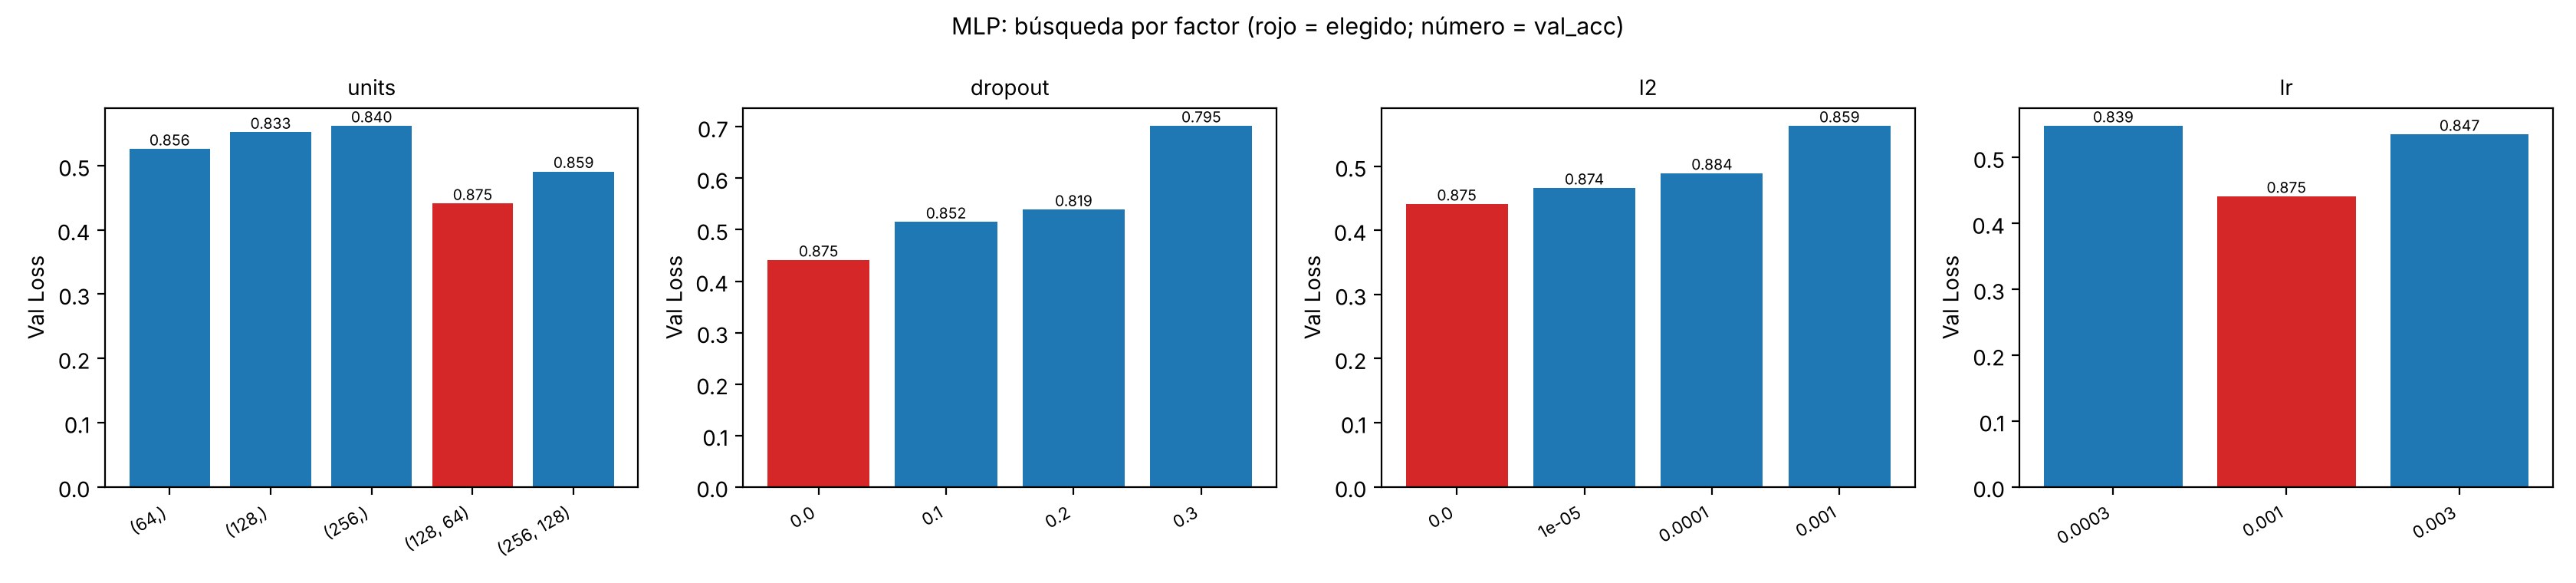

In [10]:
ESPACIO_MLP = [
    ('units',   [(64,), (128,), (256,), (128, 64), (256, 128)]),
    ('dropout', [0.0, 0.1, 0.2, 0.3]),
    ('l2',      [0.0, 1e-5, 1e-4, 1e-3]),
    ('lr',      [3e-4, 1e-3, 3e-3]),
]
mlp_opt, mlp_partida, df_busq_mlp, dec_mlp = busqueda_por_factores('mlp', INICIO['mlp'], ESPACIO_MLP, data, CONFIG)
display(df_busq_mlp[COLS_BUSQUEDA])
display(dec_mlp)
df_busq_mlp.to_csv(f"{CONFIG['paths']['images']}/ep3_busqueda_mlp_tabla.csv", index=False)
plot_busqueda(df_busq_mlp, 'MLP: búsqueda por factor', f"{CONFIG['paths']['images']}/ep3_busqueda_mlp.png")

**Lectura (MLP):**
- **`units` es el único factor que importa.** Pasar de (128) a **(128, 64)** baja el `val_loss` de 0,552 a 0,441 y sube la val_acc de 0,833 a 0,875 (test 0,811 → 0,868). Más profundidad ayuda más que más ancho: (256) casi no mejora la base (0,562) y (256, 128) queda segunda (0,491).
- **Dropout empeora de forma sistemática** (val_loss 0,441 / 0,515 / 0,539 / 0,702 para 0 / 0,1 / 0,2 / 0,3). Una explicación, *no verificada aquí*, es que la red es pequeña y con BatchNorm el dropout solo le resta capacidad.
- **L2:** el `val_loss` empeora al aumentar la penalización (0,441 → 0,466 → 0,489 → 0,563). Con 1e-4 la accuracy fue algo mayor (val 0,884, test 0,890), pero esa diferencia es del orden del ruido entre semillas (±1,5 puntos, ver 8.4), así que no se justifica cambiar a posteriori el criterio fijado. Es una discrepancia entre `val_loss` y accuracy que conviene poder explicar en la defensa.
- **Learning rate:** 1e-3 se mantiene (3e-4 → 0,548; 3e-3 → 0,535).
- La MLP optimizada sigue sobreajustando (brecha 0,125) y sigue lejos de la CNN.

### 8.2 Búsqueda para la CNN
Cada entrenamiento de la CNN con augmentation tarda varios minutos, por eso el espacio es más acotado que el de la MLP.

[cnn] aug_translation  -> 0.05         (val_loss 0.022 -> 0.01)


[cnn] dropout          -> 0.3          (val_loss 0.01 -> 0.009)


[cnn] l2               -> 0.0          (val_loss 0.009 -> 0.009)


[cnn] lr               -> 0.001        (val_loss 0.009 -> 0.009)


[cnn] filters          -> (32, 64, 128) (val_loss 0.009 -> 0.0)


,Factor,Valor,Elegido,Épocas,Tiempo (s),Val Loss,Val Acc,Train Acc,Brecha train-val,Test Acc,Test F1
0,aug_translation,0.05,True,20,98.5,0.010,1.000,0.987,-0.013,1.000,1.000
1,aug_translation,0.1,False,32,157.1,0.022,0.992,0.990,-0.002,0.991,0.991
2,aug_translation,0.2,False,18,72.8,0.222,0.936,0.870,-0.066,0.937,0.935
3,dropout,0.0,False,20,98.5,0.010,1.000,0.987,-0.013,1.000,1.000
4,dropout,0.3,True,26,119.5,0.009,0.999,0.976,-0.023,0.999,0.999
5,l2,0.0,True,26,119.5,0.009,0.999,0.976,-0.023,0.999,0.999
6,l2,0.0001,False,22,106.2,0.053,1.000,0.972,-0.028,0.999,0.999
7,l2,0.001,False,40,201.1,0.141,0.999,0.977,-0.022,0.997,0.997
8,lr,0.0005,False,23,116.2,0.027,0.998,0.966,-0.032,0.997,0.996
9,lr,0.001,True,26,119.5,0.009,0.999,0.976,-0.023,0.999,0.999


,Factor,Valor elegido,Val Loss antes,Val Loss después
0,aug_translation,0.05,0.022,0.010
1,dropout,0.3,0.010,0.009
2,l2,0.0,0.009,0.009
3,lr,0.001,0.009,0.009
4,filters,"(32, 64, 128)",0.009,0.000


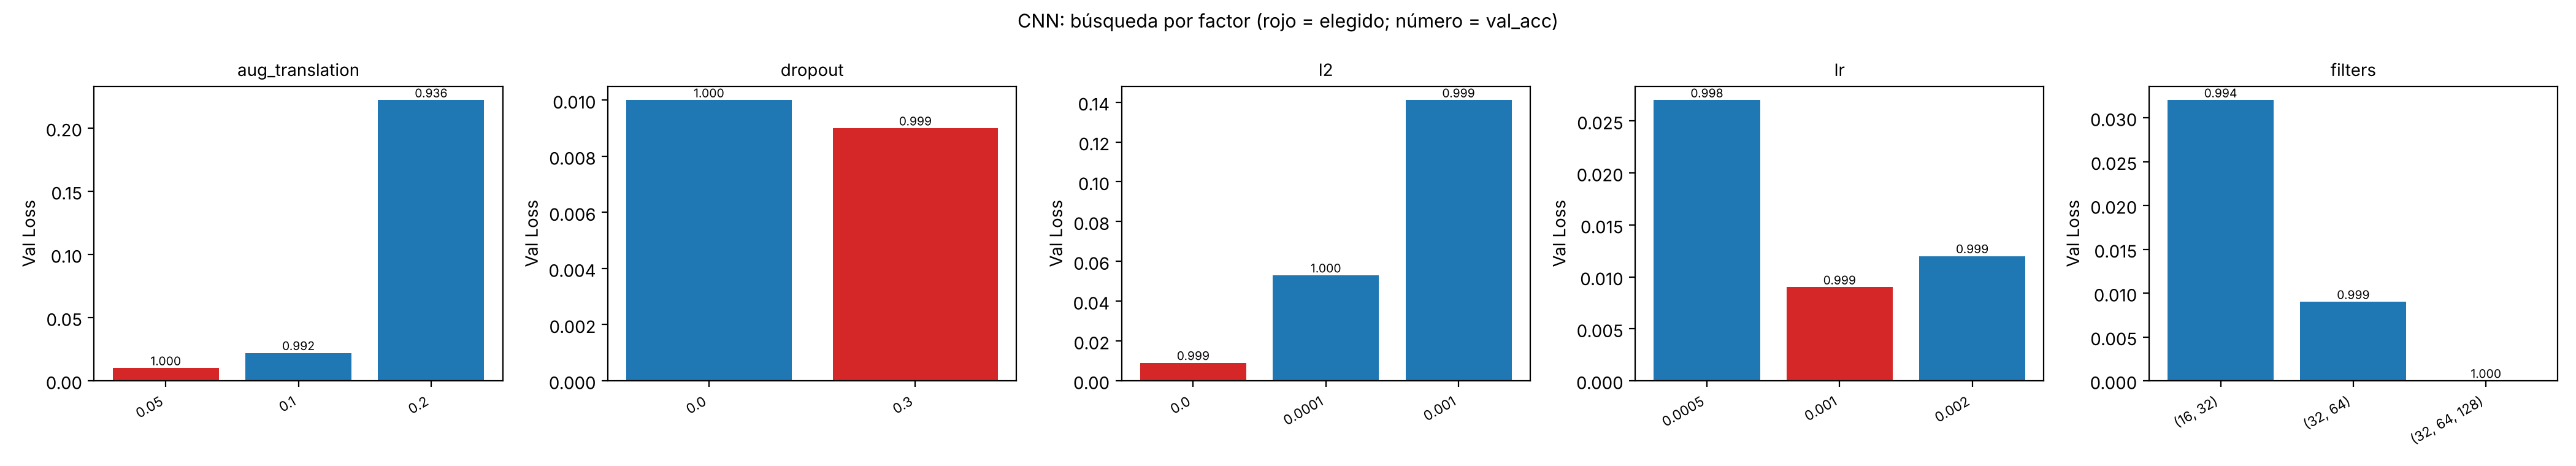

In [11]:
ESPACIO_CNN = [
    ('aug_translation', [0.05, 0.1, 0.2]),
    ('dropout',         [0.0, 0.3]),
    ('l2',              [0.0, 1e-4, 1e-3]),
    ('lr',              [5e-4, 1e-3, 2e-3]),
    ('filters',         [(16, 32), (32, 64), (32, 64, 128)]),
]
CONFIG_CNN = {**CONFIG, 'epochs': 40}
cnn_opt, cnn_partida, df_busq_cnn, dec_cnn = busqueda_por_factores('cnn', INICIO['cnn'], ESPACIO_CNN, data, CONFIG_CNN)
display(df_busq_cnn[COLS_BUSQUEDA])
display(dec_cnn)
df_busq_cnn.to_csv(f"{CONFIG['paths']['images']}/ep3_busqueda_cnn_tabla.csv", index=False)
plot_busqueda(df_busq_cnn, 'CNN: búsqueda por factor', f"{CONFIG['paths']['images']}/ep3_busqueda_cnn.png")

**Lectura (CNN):**
- **Traslación del augmentation:** 0,05 es la mejor (val_loss 0,010), seguida de 0,10 (0,022). Con **0,20 empeora mucho** (val_acc 0,936): un augmentation demasiado agresivo deforma las imágenes más allá de lo que se ve en validación y test.
- **Filtros (32, 64, 128):** la tercera capa convolucional reduce el mapa de características antes de aplanar, así que el modelo es **más profundo pero con menos parámetros** (241.030 vs 421.126) y entrena más rápido (137 s vs 157 s). (16, 32) es claramente peor (val_loss 0,032, test 0,985).
- **L2 no ayuda** (0,053 con 1e-4 y 0,141 con 1e-3) y **lr 1e-3 se mantiene**.
- **Dropout 0,3 vs 0:** 0,009 contra 0,010. Esa diferencia no significa nada; se elige 0,3 por el criterio fijado, pero es prácticamente un empate.
- **Saturación:** la CNN llega a val_acc 1,000 y test 1,000. Con 1.004 imágenes de validación, una diferencia de 0,1 a 0,8 puntos son entre 1 y 8 imágenes, y un `val_loss` de 0,00x ya no discrimina de forma confiable. Las elecciones informativas son las que **empeoran claramente** (traslación 0,20, filtros (16, 32), L2 alto); las demás son casi empates.
- **Ojo con la robustez:** al bajar la traslación del augmentation de 0,10 a 0,05 se mejora en validación y test, que están centrados como el train, pero es esperable que la CNN **pierda robustez a desplazamientos grandes**. Se vuelve a medir en la auditoría.

### 8.3 Configuración elegida frente a la de partida

=== MLP ===
Hiperparámetros elegidos: {'units': (128, 64)}


,Parámetros,Épocas,Tiempo (s),Val Loss,Val Acc,Brecha train-val,Test Acc,Test Precision,Test Recall,Test F1,Test ROC-AUC
Modelo,,,,,,,,,,,
MLP partida (BatchNorm),101638,8,3.6,0.552,0.833,0.167,0.811,0.811,0.810,0.798,0.964
MLP optimizada,109702,8,5.3,0.441,0.875,0.125,0.868,0.863,0.856,0.854,0.978


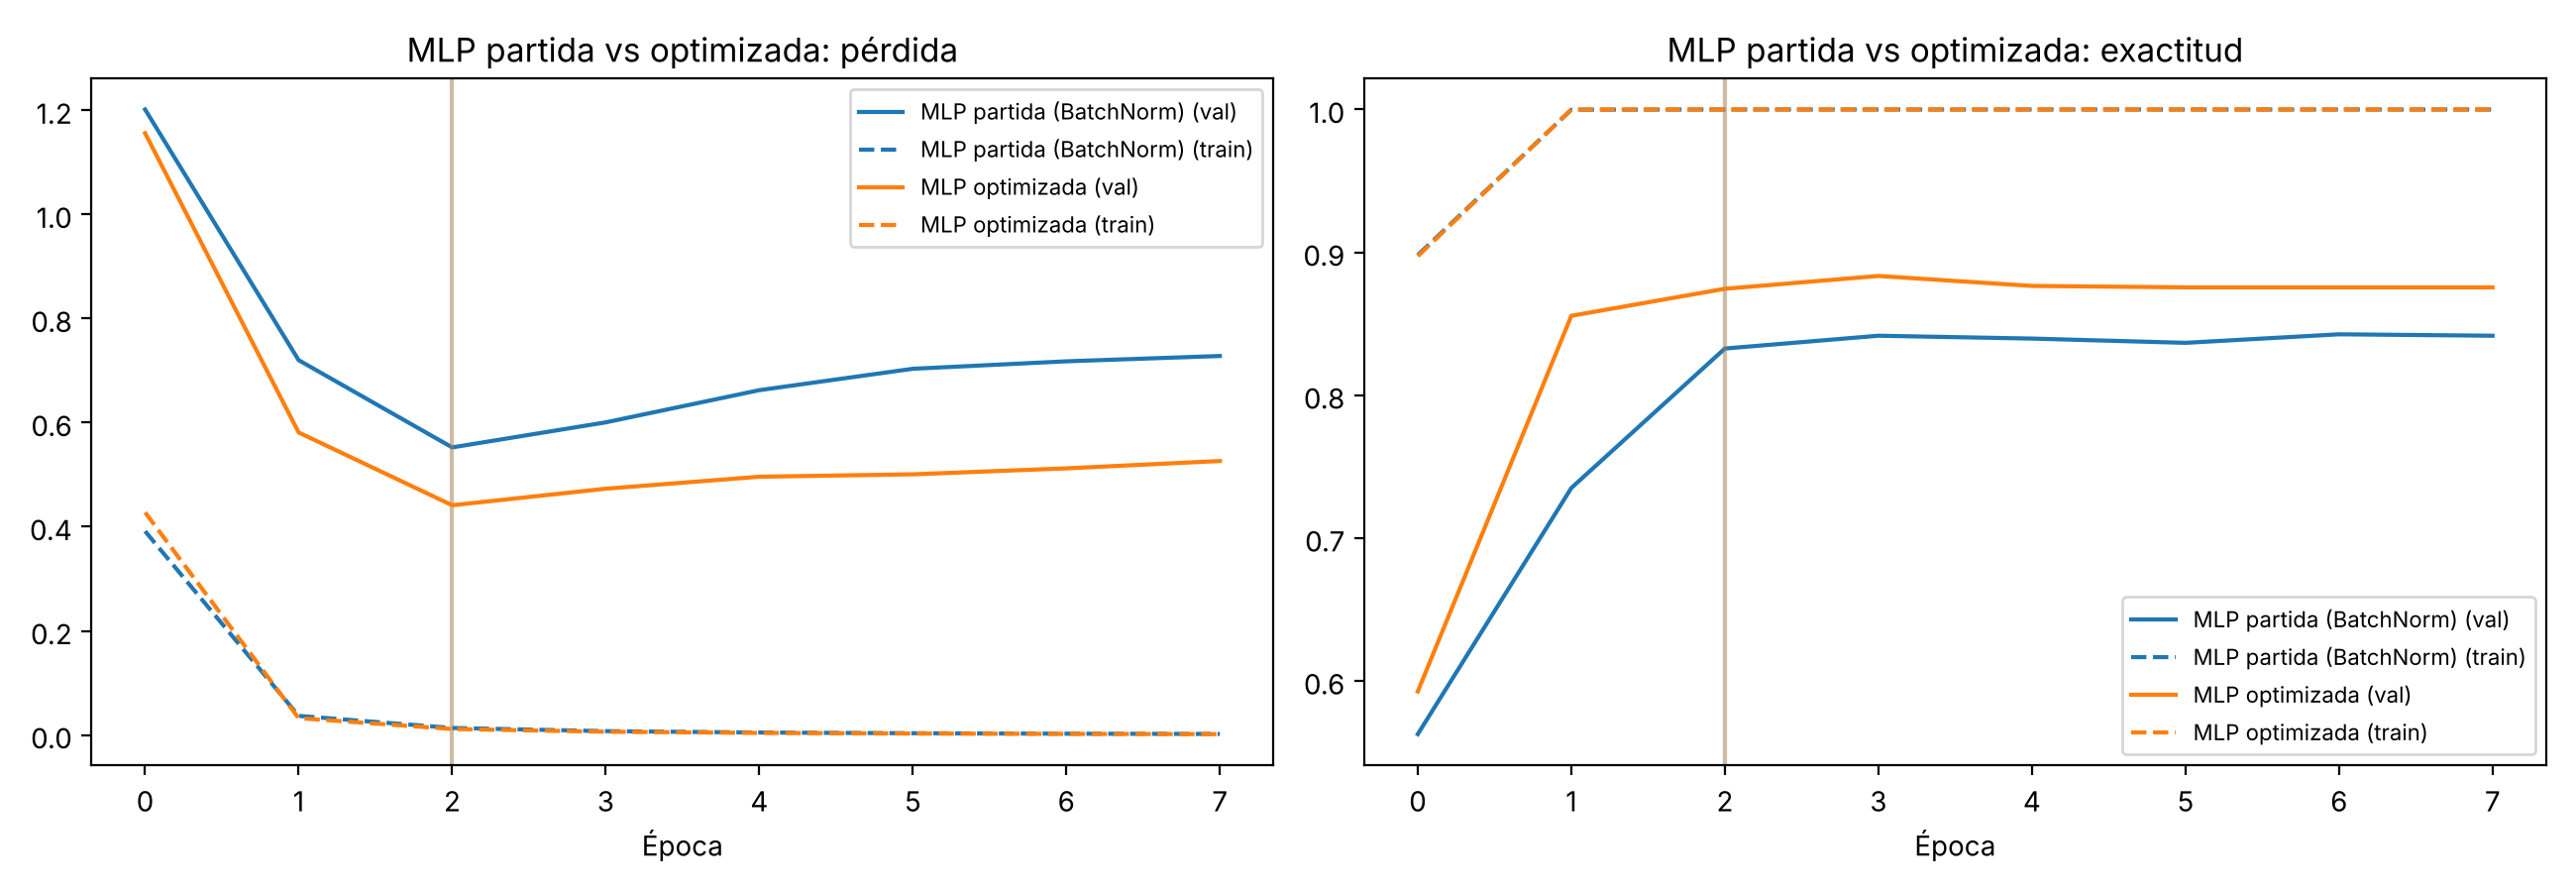

=== CNN ===
Hiperparámetros elegidos: {'filters': (32, 64, 128), 'dropout': 0.3, 'augment': {'translation': 0.05, 'rotation': 0.05, 'zoom': 0.1}}


,Parámetros,Épocas,Tiempo (s),Val Loss,Val Acc,Brecha train-val,Test Acc,Test Precision,Test Recall,Test F1,Test ROC-AUC
Modelo,,,,,,,,,,,
"CNN partida (Aug, 40 épocas)",421126,32,157.1,0.022,0.992,-0.002,0.991,0.99,0.992,0.991,1.0
CNN optimizada,241030,27,137.2,0.000,1.000,-0.005,1.000,1.00,1.000,1.000,1.0


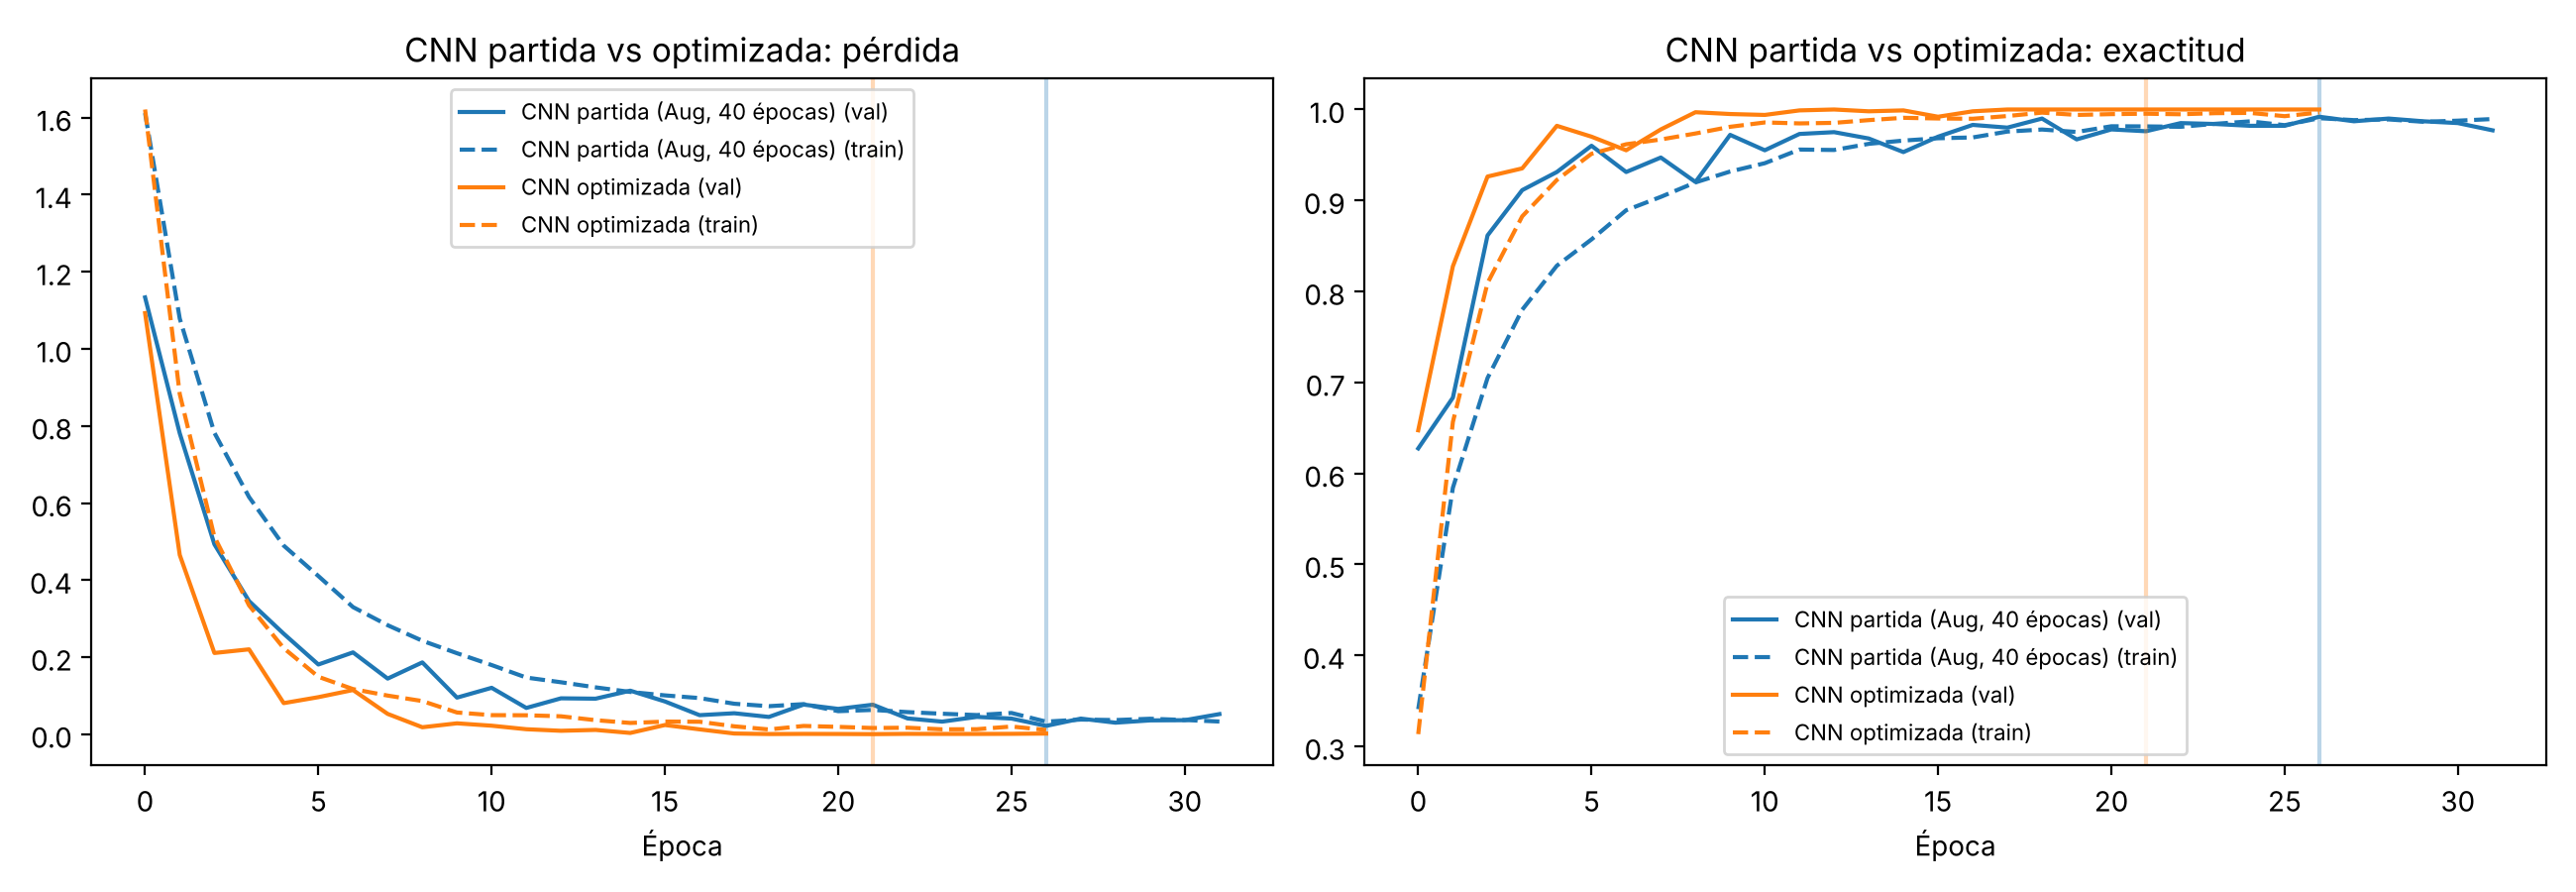

In [12]:
def renombrar(r, nombre):
    return {**r, 'name': nombre}


finales = {
    'mlp': (renombrar(mlp_partida, 'MLP partida (BatchNorm)'), renombrar(mlp_opt, 'MLP optimizada')),
    'cnn': (renombrar(cnn_partida, 'CNN partida (Aug, 40 épocas)'), renombrar(cnn_opt, 'CNN optimizada')),
}
for k, (p, o) in finales.items():
    print(f"=== {k.upper()} ===")
    print('Hiperparámetros elegidos:', {a: b for a, b in o['params'].items() if p['params'].get(a) != b or a in ('units', 'filters')})
    display(pd.DataFrame([summarize_run(p), summarize_run(o)]).set_index('Modelo')[
        ['Parámetros', 'Épocas', 'Tiempo (s)', 'Val Loss', 'Val Acc', 'Brecha train-val', 'Test Acc',
         'Test Precision', 'Test Recall', 'Test F1', 'Test ROC-AUC']])
    plot_history([p, o], save_path=f"{CONFIG['paths']['images']}/ep3_optimizacion_{k}_curvas.png",
                 title=f'{k.upper()} partida vs optimizada')

### 8.4 Confirmación con varias semillas
Una sola semilla no permite distinguir una mejora real de una fluctuación. Se repiten la configuración de partida y la elegida con 3 semillas (42, 7 y 123). **Cambia la inicialización de los pesos y el azar del augmentation; el split de datos es el mismo.**

In [13]:
SEMILLAS = [42, 7, 123]


def multi_semilla(kind, base, params, data, cfg, semillas):
    """Repite una configuración con varias semillas, reutilizando la corrida ya hecha con la semilla de cfg."""
    salida = []
    for s in semillas:
        if s == cfg['seed']:
            salida.append(base)
        else:
            salida.append(run_experiment(f'{base["name"]} (semilla {s})', kind, params, data, {**cfg, 'seed': s}))
    return salida


def resumen_semillas(grupos):
    """Media ± desviación estándar (n-1) de las métricas por configuración."""
    obtener = {'Val Loss': lambda r: min(r['history'].history['val_loss']), 'Val Acc': lambda r: r['val']['accuracy'],
               'Test Acc': lambda r: r['test']['accuracy'], 'Test F1': lambda r: r['test']['f1_macro'],
               'Test ROC-AUC': lambda r: r['test']['roc_auc_macro']}
    filas = []
    for nombre, lista in grupos.items():
        fila = {'Configuración': nombre, 'n': len(lista)}
        for m, f in obtener.items():
            v = np.array([f(r) for r in lista])
            fila[m] = f'{v.mean():.3f} ± {v.std(ddof=1):.3f}'
        filas.append(fila)
    return pd.DataFrame(filas).set_index('Configuración')


grupos = {}
for k, cfg_k in [('mlp', CONFIG), ('cnn', CONFIG_CNN)]:
    p, o = finales[k]
    grupos[p['name']] = multi_semilla(k, p, p['params'], data, cfg_k, SEMILLAS)
    grupos[o['name']] = multi_semilla(k, o, o['params'], data, cfg_k, SEMILLAS)
df_semillas = resumen_semillas(grupos)
display(df_semillas)
df_semillas.to_csv(f"{CONFIG['paths']['images']}/ep3_confirmacion_semillas.csv")

,n,Val Loss,Val Acc,Test Acc,Test F1,Test ROC-AUC
Configuración,,,,,,
MLP partida (BatchNorm),3,0.551 ± 0.007,0.831 ± 0.018,0.826 ± 0.014,0.810 ± 0.011,0.961 ± 0.002
MLP optimizada,3,0.470 ± 0.026,0.867 ± 0.011,0.857 ± 0.015,0.845 ± 0.013,0.975 ± 0.005
"CNN partida (Aug, 40 épocas)",3,0.009 ± 0.011,0.997 ± 0.005,0.997 ± 0.005,0.997 ± 0.005,1.000 ± 0.000
CNN optimizada,3,0.001 ± 0.001,1.000 ± 0.000,1.000 ± 0.001,1.000 ± 0.001,1.000 ± 0.000


**Lectura (3 semillas, media ± desviación estándar con n = 3):**

| | Test Acc | Test F1 | Test ROC-AUC |
|---|---|---|---|
| MLP partida | 0,826 ± 0,014 | 0,810 ± 0,011 | 0,961 ± 0,002 |
| **MLP optimizada** | **0,857 ± 0,015** | **0,845 ± 0,013** | **0,975 ± 0,005** |
| CNN partida | 0,997 ± 0,005 | 0,997 ± 0,005 | 1,000 |
| **CNN optimizada** | **1,000 ± 0,001** | **1,000 ± 0,001** | **1,000** |

- **MLP:** la mejora es real, pero **más modesta que la de la semilla 42**: unos +3 puntos de accuracy (≈ 2 desviaciones estándar), no los +5,7 de esa sola corrida. Por eso conviene reportar siempre varias semillas.
- **CNN:** la diferencia de accuracy (0,997 → 1,000) está dentro del ruido, así que **no se puede afirmar que la optimización mejore la accuracy de la CNN**. Lo que sí ganó es eficiencia (42% menos parámetros) y, probablemente, estabilidad (menor dispersión entre semillas). Con solo 3 semillas esa estimación es gruesa.

---
### Conclusión del paso 3 (optimización)
1. **MLP optimizada:** capas (128, 64) con BatchNorm, sin dropout ni L2, lr 1e-3. **CNN optimizada:** filtros (32, 64, 128), dense 128, dropout 0,3, augmentation con traslación 0,05 (rotación 0,05 y zoom 0,1 sin cambios), lr 1e-3. Quedan guardadas en `models/` junto con sus hiperparámetros.
2. **Todas las decisiones se tomaron con evidencia de validación** (tablas por factor, `val_loss` como criterio fijado de antemano) y se confirmaron con varias semillas.
3. **Límite de lo que se puede concluir:** con las métricas actuales la CNN está saturada (~100%) y validación y test comparten las mismas manos, así que ese 100% **no es evidencia de generalización a personas nuevas**. Para distinguir de verdad ambas arquitecturas hacen falta pruebas de robustez, XAI y análisis de sesgos, que son el contenido de la auditoría.
4. **Limitaciones del método:** la búsqueda por factor no explora interacciones, depende del orden de los factores y no incluye rotación, zoom, tamaño del batch ni `dense_units`.

### 8.5 Guardado de los modelos finales
Se guardan la MLP optimizada y la CNN optimizada (semilla 42) y sus hiperparámetros, para reutilizarlos en la auditoría y en la explicabilidad sin volver a entrenar.

In [14]:
import json

mlp_opt['model'].save(f"{CONFIG['paths']['models']}/mlp_optimizada.keras")
cnn_opt['model'].save(f"{CONFIG['paths']['models']}/cnn_optimizada.keras")
with open(f"{CONFIG['paths']['models']}/hiperparametros_finales.json", 'w', encoding='utf-8') as f:
    json.dump({'mlp': mlp_opt['params'], 'cnn': cnn_opt['params'], 'semilla': CONFIG['seed'],
               'epochs_cnn': CONFIG_CNN['epochs']}, f, indent=2, default=list)
print(os.listdir(CONFIG['paths']['models']))

['hiperparametros_finales.json', 'cnn_optimizada.keras', 'mlp_optimizada.keras', 'mejor_modelo_cnn.keras', 'mejor_modelo_mlp.keras']


## 9. Estado del pipeline y siguientes pasos
Quedan funcionando las etapas de carga, EDA, preprocesamiento, construcción, entrenamiento, regularización, optimización y evaluación (con ROC-AUC), todas con funciones reutilizables, más las líneas base trazables con la EP1 y la EP2 y los dos modelos optimizados guardados en `models/`.

**Pendiente en el notebook (por paso):**
1. **Auditoría (etapa 8):** reporte y matriz de confusión de los modelos finales, pruebas de robustez (traslación, ruido, brillo) y análisis de sesgos con medidas de mitigación.
2. **XAI:** Grad-CAM en la CNN y un segundo método (SHAP o LIME) en la MLP, para comparar explicabilidad.
3. **Comparación final MLP optimizada vs CNN final:** métricas, generalización, explicabilidad y tiempos, con justificación del modelo recomendado.
4. **Conclusiones** y evaluación crítica del pipeline.